# TP 3- Clasificación multiclase de texto con Multilayer Perceptron + Regularización
### Redes Neuronales para Bioingeniería

Dataset: **20 Newsgroups** (~18.000 posts de foros de Usenet, clasificados en 20 categorías).

## Consigna
A partir de las recomendaciones y los conceptos teóricos abordados durante las clases de regularización, se deberán incorporar y evaluar las siguientes estrategias como posibles hiperparámetros en el Trabajo Práctico de Clasificación de **20 Newsgroups (TNG)**:

- **Regularización L1 y L2**, tanto individualmente como en combinación (L1 + L2).
- **Dropout**.
- **Batch Normalization**.

Para cada estrategia, se deberán realizar experimentos considerando las recomendaciones discutidas en clase y analizar su impacto sobre el comportamiento y el desempeño del modelo.

El análisis deberá contemplar especialmente los siguientes aspectos:

- **Magnitud de los pesos:** observar los valores absolutos de los pesos de la red y analizar cómo se modifican según la estrategia de regularización aplicada.
- **Tiempos de entrenamiento:** comparar la duración de los entrenamientos y evaluar el impacto de cada estrategia sobre el costo computacional.
- **Learning Rate:** analizar la influencia de la tasa de aprendizaje y su interacción con las estrategias de regularización.
- **Curvas de aprendizaje:** observar la evolución de las métricas de entrenamiento y validación, prestando especial atención al ruido, las fluctuaciones y la estabilidad de las curvas.

Finalmente, se deberán **justificar e interpretar los fenómenos observados a partir de los fundamentos teóricos desarrollados en clase**, relacionando los resultados experimentales con el comportamiento esperado de cada técnica de regularización.

## 0. Setup

In [4]:
import random
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt


from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import StratifiedKFold

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
try:
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
except Exception:
    pass

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando dispositivo:", device)


c:\Users\Camila\Documents\Regularizacion_Escobar\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Usando dispositivo: cpu


In [5]:
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Camila\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos: 20 Newsgroups


- Dataset: 20 Newsgroups (Scikit-learn), dividido en entrenamiento y prueba.

- Limpieza de metadatos: se aplicó remove=('headers', 'footers', 'quotes') para evitar data leakage (fuga de información) por datos triviales como nombres de categorías en encabezados.

- Variables clave: se extrajeron los textos planos (data), sus etiquetas numéricas (target), los nombres de clases (target_names) y el total de categorías a clasificar (NUM_CLASSES).

In [6]:
newsgroups_train = fetch_20newsgroups(subset="train", remove=("headers", "footers", "quotes"))
newsgroups_test  = fetch_20newsgroups(subset="test",  remove=("headers", "footers", "quotes"))

class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)
print(f"Clases ({NUM_CLASSES}):", class_names)
print(f"\nTrain: {len(newsgroups_train.data)} documentos | Test: {len(newsgroups_test.data)} documentos")

print("\n--- Ejemplo de documento ---")
print("Categoría:", class_names[newsgroups_train.target[0]])
print(newsgroups_train.data[0][:500])


Clases (20): ['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']

Train: 11314 documentos | Test: 7532 documentos

--- Ejemplo de documento ---
Categoría: rec.autos
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.


## 2. Preprocesamiento configurable

- Pipeline de limpieza: función preprocess_text que convierte a minúsculas, tokeniza (word_tokenize) y conserva solo tokens alfabéticos.

- Control de stopwords: opción remove_stopwords (True/False) para filtrar palabras vacías en inglés de baja carga semántica.

- Normalización: opción normalization para elegir entre "none", "stem" (PorterStemmer, truncamiento heurístico) o "lemmatize" (WordNetLemmatizer, reducción a lema de diccionario).

- Salida: reconstruye el texto procesado en un string separado por espacios, listo para vectorización.

In [7]:
STOP_WORDS = set(stopwords.words("english"))
STEMMER = PorterStemmer()
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text, remove_stopwords, normalization):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha()]

    # TODO: si remove_stopwords es True, filtrar los tokens que están en STOP_WORDS
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOP_WORDS]

    # TODO: aplicar la normalización correspondiente según el valor de `normalization`
    if normalization == "stem":
        tokens = [STEMMER.stem(t) for t in tokens]

    elif normalization == "lemmatize":
        tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    # si normalization == "none", no se hace nada más

    return " ".join(tokens)


Una vez armada la función de preprocesamiento, se prueban las 6 distintas configuraciones que surgen de seleccionar los parámetros de entrada de la función `preprocess_text`.

In [8]:
# Sanity check: probamos las distintas combinaciones sobre una oración de ejemplo
ejemplo = "The researchers were studying the running processes and stopping conditions of the engines."
for norm in ["none", "stem", "lemmatize"]:
    for rm_sw in [False, True]:
        resultado = preprocess_text(ejemplo, remove_stopwords=rm_sw, normalization=norm)
        print(f"normalization={norm:10s} remove_stopwords={str(rm_sw):5s} -> {resultado}")


normalization=none       remove_stopwords=False -> the researchers were studying the running processes and stopping conditions of the engines
normalization=none       remove_stopwords=True  -> researchers studying running processes stopping conditions engines
normalization=stem       remove_stopwords=False -> the research were studi the run process and stop condit of the engin
normalization=stem       remove_stopwords=True  -> research studi run process stop condit engin
normalization=lemmatize  remove_stopwords=False -> the researcher were studying the running process and stopping condition of the engine
normalization=lemmatize  remove_stopwords=True  -> researcher studying running process stopping condition engine


## 3. Vectorización TF-IDF

- Vectorización (TfidfVectorizer): transforma el texto preprocesado en matrices numéricas dispersas representando el peso $TF\text{-}IDF$ de cada término en el documento.
- Control del vocabulario: 
    - `ngram_range` controla si se utilizan unigramas (1,1) o si se agregan bigramas (1,2) para capturar contexto local.
    - `max_features`: define el tamaño máximo del vocabulario.
    - `min_df`: exige que un término aparezca en un mínimo de documentos para ser incluido, filtrando errores y términos atípicos.
- Prevención de data leakage: se aplica `.fit_transform()` únicamente sobre el conjunto de entrenamiento (train_texts) para construir el vocabulario, y sobre los datos de validación (test_texts) se ejecuta exclusivamente `.transform()`.

In [9]:
def vectorize_data(train_texts, test_texts, ngram_range, max_features, min_df):

    vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df
    )
    X_train = vectorizer.fit_transform(train_texts) #FIT y TRANSFORM
    X_test = vectorizer.transform(test_texts) #SOLO TRANSFORM, NUNCA FIT.

    return X_train, X_test, vectorizer

In [10]:
# Sanity check rápido con pocos documentos
_sample_train = ["the cat sat on the mat", "dogs are running in the park", "cats and dogs are pets"]
_sample_test = ["the dog sat on the mat"]
_Xtr, _Xte, _vec = vectorize_data(_sample_train, _sample_test, ngram_range=(1, 1), max_features=50, min_df=1)
assert _Xtr is not None, "Completá vectorize_data"
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)
print("Vocabulario (parcial):", list(_vec.vocabulary_.keys())[:10])


Shape train: (3, 13) | Shape test: (1, 13)
Vocabulario (parcial): ['the', 'cat', 'sat', 'on', 'mat', 'dogs', 'are', 'running', 'in', 'park']


## 4. Modelo MLP

Para superar las limitaciones de la Regresión Softmax, que al ser un modelo lineal solo puede resolver problemas linealmente separables, implementamos un Perceptrón Multicapa (MLP, del inglés $Multilayer Perceptron$). 

La clave del MLP es que introduce capas ocultas con funciones de activación no lineales. Esto permite proyectar los datos de entrada a un espacio de mayor complejidad donde sí es posible trazar fronteras de decisión separables, respaldado por el Teorema de Aproximación Universal.  

Para poder probar distintas arquitecturas durante la exploración de hiperparámetros con Optuna, armamos la clase `MLPConfigurable`.

La inicialización incluye como parámetros de entrada:
- `ìnput_dim`: dimensión de los datos de entrada (vocabulario).
- `hidden_units`: cantidad de neuronas para cada una de las capas ocultas.
- `num_classes`: cantidad de clases a clasificar (20 para 20 Newsgroups).
- `activation_name`: define el tipo de función de activación no lineal a utilizar (sigmoidea, ReLU, tangente hiperbólica, etc).
  
A su vez, se incluye un diccionario con las distintas funciones de activaciones, mapeando la elección con la función correspondiente de PyTorch.

Luego se arman las capas:
- `nn.Linear(input_dim, neuronas)`: es la transformación $z = WX + \omega_0$ (multiplicación por matriz de pesos $W$ más el bias $\omega_0$). Convierte un espacio de tamaño input_dim a un espacio intermedio de tamaño neuronas.   
- `capas.append(f_act)`: añade la función no lineal seleccionada justo después de la capa lineal. Sin esta activación, la combinación de varias capas lineales colapsaría en una sola multiplicación lineal equivalente.   - `input_dim = neuronas`: reasigna la dimensión para que la siguiente capa sepa cuántas entradas recibir de la capa anterior.

Finalmente, se arma la última capa, con 20 salidas en este caso. `nn.Sequential(*capas)` toma la lista de capas y funciones de activación y las empaqueta en un solo bloque secuencial. 

In [13]:
class MLPConfigurable(nn.Module):
    def __init__(self, input_dim, hidden_units, num_classes, activation_name):
        """
        - input_dim: cantidad de features.
        - hidden_units: neuronas por capa.
        - num_classes: 20 (las 20 clases de 20Newsgroups)
        - activation_name: 'relu','sigmoid','tanh','elu','leaky_relu'
        """
        super().__init__()

        # 1. Selección de la función de activación
        activaciones = {
            "sigmoid": nn.Sigmoid(),
            "relu": nn.ReLU(),
            "tanh":nn.Tanh(),
            "elu": nn.ELU(),
            "leaky_relu": nn.LeakyReLU()
        }

        # Busca en activaciones y guarda la función de activación seleccionada
        f_act = activaciones[activation_name.lower()]

        capas=[]
        input_dim = input_dim #Guarda la dimensión de entrada de la capa.

        
        # 2. Armado de las capas ocultas (1, 2 o 3 capas)
        for neuronas in hidden_units:
            capas.append(nn.Linear(input_dim, neuronas)) # Capa de pesos
            capas.append(f_act)                          # Activación elegida
            input_dim = neuronas                         # Actualización de la cantidad de entradas para la capa siguiente
        
        # 3. Agregado de la capa de salida (20 clases)
        capas.append(nn.Linear(input_dim, num_classes))

        # 4. Empaquetado en una sola secuencia
        self.red = nn.Sequential(*capas)

    def forward(self, x):
        return self.red(x)

## 5. Entrenamiento 

Dado que los datos vectorizados entran en memoria sin problema, armamos `DataLoader`s a partir de tensores densos. Logueamos loss y accuracy (train y validación) por época a TensorBoard, y a MLflow además los hiperparámetros y el modelo final.

**DETALLE DEL BLOQUE**

La función `to_tensor_dataset` convierte los datos TF-IDF y sus etiquetas a tensores de PyTorch y los agrupa en un `TensorDataset`.

La función `train_model` realiza el entrenamiento y validación del modelo durante las épocas indicadas mediante `for epoch in range(epochs)`. En cada época, `model.train()` coloca el modelo en modo entrenamiento y se inicializan los contadores para acumular la pérdida y las predicciones correctas.

Luego, se recorren los datos de entrenamiento mediante `train_loader`, que entrega los documentos en batches. Los datos se trasladan al dispositivo correspondiente (CPU o GPU) mediante `.to(device)`. Antes de calcular los nuevos gradientes, `optimizer.zero_grad()` elimina los gradientes de la iteración anterior.

A continuación, se realiza el *forward pass* mediante `logits = model(xb)`. Los datos de entrada pasan por la capa lineal del modelo y se obtienen los logits correspondientes a las 20 clases. Luego, `CrossEntropyLoss` compara estos logits con las etiquetas reales y calcula la pérdida (*loss*).

Con `loss.backward()` se realiza el *backpropagation*, mediante el cual PyTorch calcula los gradientes de los parámetros del modelo respecto de la pérdida. Luego, `optimizer.step()` utiliza estos gradientes para actualizar los pesos y el bias del modelo, buscando reducir el error en las siguientes iteraciones.

Durante el entrenamiento también se acumulan las pérdidas y las predicciones correctas para calcular `train_loss` y `train_acc` al finalizar la época. La clase predicha se obtiene mediante `logits.argmax(dim=1)`, que selecciona el logit de mayor valor.

Una vez terminado el entrenamiento de la época, el modelo pasa a modo testeo mediante `model.eval()`. Se recorren los datos de validación sin modificar los parámetros del modelo. El bloque `torch.no_grad()` evita el cálculo de gradientes, ya que durante la validación no se realizan actualizaciones. De esta manera se calculan `val_loss` y `val_acc`, que permiten evaluar cómo generaliza el modelo sobre datos que no utiliza para ajustar sus pesos.

Finalmente, los valores de pérdida y accuracy de entrenamiento y validación se almacenan en `history`. Además, se registran en TensorBoard y MLflow para poder visualizar y comparar la evolución de los distintos entrenamientos.


In [14]:
def to_tensor_dataset(X, y):
    X_dense = torch.tensor(X.toarray(), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    return TensorDataset(X_dense, y_tensor)


def train_model(model, train_loader, val_loader, optimizer, epochs, writer=None, run_name="experiment",trial=None):
    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                loss = criterion(logits, yb)
                running_loss += loss.item() * xb.size(0)
                correct += (logits.argmax(dim=1) == yb).sum().item()
                total += xb.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"[{run_name}] Epoch {epoch+1}/{epochs} - "
              f"train_loss: {train_loss:.4f} train_acc: {train_acc:.4f} - "
              f"val_loss: {val_loss:.4f} val_acc: {val_acc:.4f}")

        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        mlflow.log_metric("train_loss", train_loss, step=epoch)
        mlflow.log_metric("val_loss", val_loss, step=epoch)
        mlflow.log_metric("train_acc", train_acc, step=epoch)
        mlflow.log_metric("val_acc", val_acc, step=epoch)

        # ------------------------------------------------------------------------
        # PRUNING DE OPTUNA
        # ------------------------------------------------------------------------
        if trial is not None:
            trial.report(val_acc, step=epoch) # Trial reporta a Optuna su accuracy
 
            # Si Optuna decide podar, interrumpe la ejecución de este trial
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

    return history


## 6. Búsqueda de hiperparámetros con Optuna

La búsqueda incluye **hiperparámetros de preprocesamiento** (`remove_stopwords`, `normalization`, `ngram_range`, `max_features`, `min_df`) y **de entrenamiento** (`lr`, `batch_size`), todos en un mismo `objective`.

**Optimización de tiempo**: como la tokenización + stopwords + normalización es lo más lento del pipeline (y solo depende de `remove_stopwords` y `normalization`, que tienen pocas combinaciones posibles), la precalculamos una sola vez para las 6 combinaciones posibles y la cacheamos. Así, cada trial de Optuna solo repite la parte rápida (vectorizar + entrenar pocas épocas).


**DETALLE DEL BLOQUE**

En este bloque se utiliza **Optuna** para buscar una configuración de hiperparámetros que permita obtener el mejor desempeño del modelo. Un *trial* representa un entrenamiento realizado con una determinada combinación de hiperparámetros.

Primero se precalculan las 6 combinaciones posibles de preprocesamiento, dadas por las dos opciones de eliminación de stopwords (`True` o `False`) y las tres opciones de normalización (`none`, `stem` o `lemmatize`). Estas combinaciones se guardan en `preprocessed_cache` para evitar repetir el preprocesamiento en cada prueba, ya que es la parte más lenta de pipeline.

Luego se define la función `objective`, que representa un experimento individual. En cada trial, Optuna selecciona automáticamente valores para los hiperparámetros:

* Eliminación de stopwords.
* Tipo de normalización.
* Uso de unigramas o bigramas.
* Cantidad máxima de palabras en el vocabulario (`max_features`).
* Frecuencia mínima de aparición de las palabras (`min_df`).
* Tasa de aprendizaje, learning rate (`lr`).
* Tamaño del batch (`batch_size`).

Para cada configuración se divide el conjunto de entrenamiento en un subconjunto de entrenamiento y otro de validación, manteniendo la proporción de las clases usando `stratify`. El conjunto de test no se utiliza durante esta búsqueda, ya que se reserva para la evaluación final.

Después se vectorizan los textos mediante TF-IDF, se crean los `DataLoader` y se construye un nuevo modelo de Regresión Softmax. El modelo se entrena durante 5 épocas utilizando el optimizador Adam y la tasa de aprendizaje seleccionada por Optuna.

Al finalizar cada trial, se devuelve el `val_acc` de la última época. Optuna utiliza este valor como objetivo para comparar las diferentes configuraciones y, dado que `direction="maximize"`, busca maximizar la accuracy de validación.

Finalmente, `study.best_params` muestra la combinación de hiperparámetros que obtuvo el mejor resultado y `study.best_value` muestra la mejor accuracy de validación encontrada.

Así, Optuna permite automatizar la exploración de distintas configuraciones de hiperparámetros, en lugar de probar manualmente cada combinación.



In [15]:
def tracked(objective, prefix):
    def wrapper(trial):
        # nested=True permite abrir un Run hijo si ya existe un Run activo
        with mlflow.start_run(run_name=f"{prefix}_trial_{trial.number}", nested=True):
            try:
                return objective(trial)
            finally:
                mlflow.log_params(trial.params)
    return wrapper

In [16]:
print("Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...")
preprocessed_cache = {}
for remove_stopwords in [False, True]:
    for normalization in ["none", "stem", "lemmatize"]:
        key = (remove_stopwords, normalization)
        train_proc = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_train.data]
        test_proc  = [preprocess_text(t, remove_stopwords, normalization) for t in newsgroups_test.data]
        preprocessed_cache[key] = (train_proc, test_proc)
        print("  listo:", key)


Precalculando preprocesamiento para las 6 combinaciones posibles (puede tardar unos minutos)...
  listo: (False, 'none')
  listo: (False, 'stem')
  listo: (False, 'lemmatize')
  listo: (True, 'none')
  listo: (True, 'stem')
  listo: (True, 'lemmatize')


Adaptación y agregados para búsqueda de hiperparámetros en MLP (esto es del TP2, no borré las explicaciones):
1. Exploración dinámica de la arquitectura de red:
    - Profundidad (`num_layers`): Optuna elige entre 1, 2 o 3 capas ocultas. 
    - Ancho por capa (`hidden_units`): mediante un bucle for, define independientemente la cantidad de neuronas para cada capa previa (units_layer_i), evaluando entre 64, 128, 256 y 512 unidades.
    - Funciones de activación (activation): explora de forma categórica la función no lineal a utilizar (relu, sigmoid, tanh, elu, leaky_relu).
2. Selección y configuración dinámica del optimizador: ya no se limita a usar un único optimizador fijo; ahora prueba entre Adam, RMSprop y SGD (Softmax usaba solo Adam). 
    - Optimización de hiperparámetros internos de los optimizadores:
        - Adam: optimiza los momentos de orden 1 (beta1 entre 0.8 y 0.99) y orden 2 (beta2 entre 0.9 y 0.9999).
        - RMSprop: ajusta la tasa de decaimiento del promedio móvil (alpha) y el parámetro de impulso (momentum).
        - SGD: explora el valor óptimo de impulso (momentum).

3. Estrategia de pruning early stopping (MedianPruner): se incorporó el podador de Optuna (optuna.pruners.MedianPruner(n_warmup_steps=2)), que evalúa en tiempo real la accuracy de validación durante las épocas. Si en la época 2 o posterior el trial rinde por debajo de la mediana de todas las corridas anteriores, Optuna interrumpe (poda) el entrenamiento inmediatamente. Esto ahorra tiempo de cómputo evitando terminar entrenamientos poco prometedores.
   
4. Instanciación modular: se invoca a la clase MLPConfigurable pasándole la lista construida de hidden_units y la función de activación seleccionada para adaptar la red al paso actual.

In [18]:
def objective_mlp(trial):
    # -------------------------------------------------------------------------
    # 1. Hiperparámetros de Preprocesamiento de Texto (reusando preprocessed_cache)
    # -------------------------------------------------------------------------
    remove_stopwords = trial.suggest_categorical("remove_stopwords", [False, True])
    normalization = trial.suggest_categorical("normalization", ["none", "stem", "lemmatize"])
    ngram_range = trial.suggest_categorical("ngram_range", ["1gram", "1_2gram"])
    ngram_range_tuple = (1, 1) if ngram_range == "1gram" else (1, 2)
    max_features = trial.suggest_categorical("max_features", [2000, 5000, 10000])
    min_df = trial.suggest_categorical("min_df", [1, 2, 5])

    # -------------------------------------------------------------------------
    # 2. Hiperparámetros de Entrenamiento General
    # -------------------------------------------------------------------------
    batch_size = trial.suggest_categorical("batch_size", [32, 64, 128])

    # -------------------------------------------------------------------------
    # 3. Hiperparámetros de la Arquitectura MLP (Capas, Neuronas y Activación)
    # -------------------------------------------------------------------------
    num_layers = trial.suggest_int("num_layers", 1, 3)
    hidden_units = []
    for i in range(num_layers):
        units = trial.suggest_categorical(f"units_layer_{i}", [64, 128, 256, 512])
        hidden_units.append(units)
        
    activation_name = trial.suggest_categorical("activation", ["relu", "sigmoid", "tanh", "elu", "leaky_relu"])

    # -------------------------------------------------------------------------
    # 4. Hiperparámetros de Optimizador y Momentos de Orden 1 y 2
    # -------------------------------------------------------------------------
    optimizer_name = trial.suggest_categorical("optimizer", ["Adam", "RMSprop", "SGD"])

    # -------------------------------------------------------------------------
    # 5. Carga de Datos, Split y Vectorización TF-IDF
    # -------------------------------------------------------------------------
    train_texts, _ = preprocessed_cache[(remove_stopwords, normalization)]
    
    tr_texts, val_texts, tr_labels, val_labels = train_test_split(
        train_texts, 
        newsgroups_train.target, 
        test_size=0.2, 
        random_state=SEED,
        stratify=newsgroups_train.target
    )

    X_tr, X_val, _ = vectorize_data(tr_texts, val_texts, ngram_range_tuple, max_features, min_df)
    
    train_loader = DataLoader(to_tensor_dataset(X_tr, tr_labels), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(to_tensor_dataset(X_val, val_labels), batch_size=batch_size, shuffle=False)

    # -------------------------------------------------------------------------
    # 6. Instanciación del Modelo MLPConfigurable
    # -------------------------------------------------------------------------
    model = MLPConfigurable(
        input_dim=X_tr.shape[1],
        hidden_units=hidden_units,
        num_classes=NUM_CLASSES,
        activation_name=activation_name
    )

    # -------------------------------------------------------------------------
    # 7. Selección del Optimizador y Momentos Específicos
    # -------------------------------------------------------------------------
    if optimizer_name == "Adam":
        # Orden 1: beta1, Orden 2: beta2
        lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
        beta1 = trial.suggest_float("adam_beta1", 0.8, 0.99)
        beta2 = trial.suggest_float("adam_beta2", 0.9, 0.9999)
        optimizer = optim.Adam(
            model.parameters(), 
            lr=lr, 
            betas=(beta1, beta2)
        )

    elif optimizer_name == "RMSprop":
        # Orden 2: alpha, Orden 1: momentum
        lr = trial.suggest_float("lr", 1e-4, 1e-1, log=True)
        alpha = trial.suggest_float("rmsprop_alpha", 0.8, 0.99)
        momentum = trial.suggest_float("rmsprop_momentum", 0.0, 0.9)
        optimizer = optim.RMSprop(
            model.parameters(), 
            lr=lr, 
            alpha=alpha, 
            momentum=momentum
        )

    else:  # SGD
        # Orden 1: momentum
        lr_sgd = trial.suggest_float("lr_sgd", 1e-2, 1.0, log=True) # Se le da a SGD un rango de lr propio para hacer pasos de gradiente más grandes y competir en igualdad de condiciones con los otros optimizadores.
        momentum = trial.suggest_float("sgd_momentum", 0.0, 0.9)
        optimizer = optim.SGD(
            model.parameters(), 
            lr=lr_sgd, 
            momentum=momentum
        )

    # -------------------------------------------------------------------------
    # 8. Entrenamiento con la función genérica (run_name="experiment" por defecto)
    # -------------------------------------------------------------------------
    history = train_model(
        model=model, 
        train_loader=train_loader, 
        val_loader=val_loader, 
        optimizer=optimizer, 
        epochs=5, 
        run_name=f"mlp_trial_{trial.number}",
        trial=trial
    )

    # Optuna maximiza la métrica de accuracy en el conjunto de validación de la última época
    return history["val_acc"][-1]


# ----------------------------------------------------------------------------
# 9. Lanzamiento de la búsqueda
# ----------------------------------------------------------------------------
mlflow.set_experiment("mlp_20newsgroups")   # (fix) experimento ANTES de optimizar
study_mlp = optuna.create_study(
    study_name="mlp_20news", storage="sqlite:///optuna_mlp.db", load_if_exists=True,
    direction="maximize",
    pruner = optuna.pruners.MedianPruner(n_warmup_steps=2)    
    )
# MedianPruner calcula la mediana de los resultados de todas las corridas anteriores en la misma época.
# Si el trial actual está por debajo de esa mediana, se asume que no se va a recuperar y se "poda".
# n_warmup_steps indica a partir de qué época es posible podar (se eligió la segunda).

study_mlp.optimize(tracked(objective_mlp,"mlp"), n_trials=15)

print("\n--- MEJORES RESULTADOS MLP ---")
print("Mejor Accuracy de Validación:", study_mlp.best_value)
print("Mejores Hiperparámetros:", study_mlp.best_params)

2026/11/18 01:03:59 INFO mlflow.tracking.fluent: Experiment with name 'mlp_20newsgroups' does not exist. Creating a new experiment.
[I 2026-11-18 01:03:59,803] A new study created in RDB with name: mlp_20news


[mlp_trial_0] Epoch 1/5 - train_loss: 3.0276 train_acc: 0.0517 - val_loss: 2.9960 val_acc: 0.0526
[mlp_trial_0] Epoch 2/5 - train_loss: 3.0001 train_acc: 0.0504 - val_loss: 2.9957 val_acc: 0.0526
[mlp_trial_0] Epoch 3/5 - train_loss: 2.9996 train_acc: 0.0517 - val_loss: 2.9955 val_acc: 0.0526
[mlp_trial_0] Epoch 4/5 - train_loss: 2.9990 train_acc: 0.0491 - val_loss: 2.9944 val_acc: 0.0530


[I 2026-11-18 01:04:06,691] Trial 0 finished with value: 0.05170128148475475 and parameters: {'remove_stopwords': True, 'normalization': 'stem', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 1, 'batch_size': 32, 'num_layers': 3, 'units_layer_0': 128, 'units_layer_1': 256, 'units_layer_2': 256, 'activation': 'sigmoid', 'optimizer': 'SGD', 'lr_sgd': 0.3266425551715931, 'sgd_momentum': 0.6385959964812995}. Best is trial 0 with value: 0.05170128148475475.


[mlp_trial_0] Epoch 5/5 - train_loss: 2.9988 train_acc: 0.0530 - val_loss: 2.9953 val_acc: 0.0517
[mlp_trial_1] Epoch 1/5 - train_loss: 2.6171 train_acc: 0.4429 - val_loss: 2.0361 val_acc: 0.6036
[mlp_trial_1] Epoch 2/5 - train_loss: 1.4762 train_acc: 0.7161 - val_loss: 1.2788 val_acc: 0.6933
[mlp_trial_1] Epoch 3/5 - train_loss: 0.8963 train_acc: 0.7943 - val_loss: 1.0450 val_acc: 0.7114
[mlp_trial_1] Epoch 4/5 - train_loss: 0.6297 train_acc: 0.8479 - val_loss: 0.9704 val_acc: 0.7221


[I 2026-11-18 01:04:15,581] Trial 1 finished with value: 0.7167476800707026 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 5000, 'min_df': 1, 'batch_size': 32, 'num_layers': 1, 'units_layer_0': 128, 'activation': 'elu', 'optimizer': 'Adam', 'lr': 0.0008189555158036926, 'adam_beta1': 0.9834787768670252, 'adam_beta2': 0.988057602253496}. Best is trial 1 with value: 0.7167476800707026.


[mlp_trial_1] Epoch 5/5 - train_loss: 0.4600 train_acc: 0.8967 - val_loss: 0.9542 val_acc: 0.7167
[mlp_trial_2] Epoch 1/5 - train_loss: 2.4556 train_acc: 0.2041 - val_loss: 1.8978 val_acc: 0.3783
[mlp_trial_2] Epoch 2/5 - train_loss: 1.4793 train_acc: 0.5203 - val_loss: 1.4216 val_acc: 0.5572
[mlp_trial_2] Epoch 3/5 - train_loss: 1.0482 train_acc: 0.6721 - val_loss: 1.3474 val_acc: 0.5983
[mlp_trial_2] Epoch 4/5 - train_loss: 0.8222 train_acc: 0.7537 - val_loss: 1.3684 val_acc: 0.6160


... (22 outputs left out)

[I 2026-11-18 01:07:08,746] Trial 13 finished with value: 0.7048166151126822 and parameters: {'remove_stopwords': False, 'normalization': 'lemmatize', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'batch_size': 32, 'num_layers': 1, 'units_layer_0': 512, 'activation': 'elu', 'optimizer': 'Adam', 'lr': 0.00178392695320944, 'adam_beta1': 0.9258010049433604, 'adam_beta2': 0.9601237749652297}. Best is trial 9 with value: 0.7207247017233761.


[mlp_trial_13] Epoch 5/5 - train_loss: 0.1012 train_acc: 0.9701 - val_loss: 1.3747 val_acc: 0.7048
[mlp_trial_14] Epoch 1/5 - train_loss: 3.0109 train_acc: 0.0568 - val_loss: 2.9816 val_acc: 0.0968
[mlp_trial_14] Epoch 2/5 - train_loss: 2.9420 train_acc: 0.1034 - val_loss: 2.8240 val_acc: 0.1631


[I 2026-11-18 01:07:15,190] Trial 14 pruned. 


[mlp_trial_14] Epoch 3/5 - train_loss: 2.3957 train_acc: 0.3132 - val_loss: 2.0649 val_acc: 0.4317

--- MEJORES RESULTADOS MLP ---
Mejor Accuracy de Validación: 0.7207247017233761
Mejores Hiperparámetros: {'remove_stopwords': True, 'normalization': 'none', 'ngram_range': '1gram', 'max_features': 10000, 'min_df': 1, 'batch_size': 32, 'num_layers': 1, 'units_layer_0': 256, 'activation': 'sigmoid', 'optimizer': 'Adam', 'lr': 0.0015696212585344079, 'adam_beta1': 0.8985249392348211, 'adam_beta2': 0.9240086813737439}


## 7. Entrenamiento final


Una vez que Optuna halló la mejor configuración de hiperparámetros, se realiza el entrenamiento final utilizando los mismos y el set de entrenamiento.

Primero se obtiene `study.best_params`, que contiene los valores de los hiperparámetros correspondientes al mejor trial.

Estos valores se guardan en variables como `BEST_REMOVE_SW`, `BEST_NORM`, `BEST_NGRAM`, `BEST_MAX_FEATURES`, `BEST_MIN_DF`, `BEST_LR` y `BEST_BATCH_SIZE`.

Luego, se recupera el preprocesamiento correspondiente y se aplica TF-IDF nuevamente sobre los conjuntos de entrenamiento y prueba utilizando los mejores parámetros encontrados. A partir de estos datos se crean los `DataLoader` para poder entrenar y evaluar el modelo por batches.

A continuación se crea un nuevo modelo desde cero. El tamaño del vocabulario de entrada se obtiene de `X_train_final.shape[1]`, mientras que la cantidad de clases es 20. También se crea el optimizador Adam utilizando la mejor tasa de aprendizaje encontrada por Optuna.

A diferencia de los trials de Optuna, que se entrenaron durante solo 5 épocas para poder probar muchas configuraciones en un tiempo razonable, el modelo final se entrena durante 20 épocas (`EPOCHS_FINAL = 20`).

Durante este entrenamiento se registran las métricas en **TensorBoard** mediante `SummaryWriter` y en **MLflow** mediante `mlflow.log_params` y las métricas registradas dentro de `train_model`. De esta manera, además de obtener el modelo final, se puede analizar la evolución del entrenamiento y conservar la configuración utilizada.

Finalmente, `mlflow.pytorch.log_model` guarda el modelo entrenado dentro de MLflow. El parámetro `input_example` proporciona un ejemplo del formato de entrada esperado por el modelo.



In [ ]:
# -----------------------------------------------------------------------------
# 1. EXTRACCIÓN DE MEJORES HIPERPARÁMETROS DEL MLP
# -----------------------------------------------------------------------------

best_mlp = study_mlp.best_params

BEST_REMOVE_SW_mlp = best_mlp["remove_stopwords"]
BEST_NORM_mlp = best_mlp["normalization"]
BEST_NGRAM_mlp = (1, 1) if best_mlp["ngram_range"] == "1gram" else (1, 2)
BEST_MAX_FEATURES_mlp = best_mlp["max_features"]
BEST_MIN_DF_mlp = best_mlp["min_df"]
BEST_BATCH_SIZE_mlp = best_mlp["batch_size"]
BEST_ACTIVATION_mlp = best_mlp["activation"]
BEST_OPT_NAME_mlp = best_mlp["optimizer"]

# Reconstrucción de la lista de neuronas por capa y número de capas.
hidden_units = [best_mlp[f"units_layer_{i}"] for i in range(best_mlp["num_layers"])]
EPOCHS_FINAL = 20

# -----------------------------------------------------------------------------
# 2. PREPROCESAMIENTO Y VECTORIZACIÓN (Dataset Completo)
# -----------------------------------------------------------------------------
train_texts_mlp, test_texts_mlp = preprocessed_cache[(BEST_REMOVE_SW_mlp, BEST_NORM_mlp)]

train_texts, val_texts, train_labels, val_labels = train_test_split(train_texts_mlp, 
                                                                 newsgroups_train.target,
                                                                 test_size = 0.2, 
                                                                 random_state=SEED,
                                                                 stratify=newsgroups_train.target 
                                                                 )

X_train_mlp, X_val_mlp, vectorizer_mlp = vectorize_data(train_texts,
                                                        val_texts,
                                                        BEST_NGRAM_mlp,
                                                        BEST_MAX_FEATURES_mlp,
                                                        BEST_MIN_DF_mlp)

train_loader_mlp = DataLoader(
    to_tensor_dataset(X_train_mlp, train_labels),
    batch_size=BEST_BATCH_SIZE_mlp, shuffle=True
)
val_loader_mlp = DataLoader(
    to_tensor_dataset(X_val_mlp, val_labels),
    batch_size=BEST_BATCH_SIZE_mlp, shuffle=False
)

# -----------------------------------------------------------------------------
# 3. INSTANCIACIÓN DE ARQUITECTURA U OPTIMIZADOR
# -----------------------------------------------------------------------------
model_mlp_final = MLPConfigurable(
    input_dim=X_train_mlp.shape[1],
    hidden_units=hidden_units,
    num_classes=NUM_CLASSES,
    activation_name=BEST_ACTIVATION_mlp
)

# Configuración del optimizador según lo determinado or Optuna
if BEST_OPT_NAME_mlp == "Adam":
    optimizer_mlp = optim.Adam(
        model_mlp_final.parameters(), 
        lr=best_mlp["lr"], 
        betas=(best_mlp["adam_beta1"], best_mlp["adam_beta2"])
    )
elif BEST_OPT_NAME_mlp == "RMSprop":
    optimizer_mlp = optim.RMSprop(
        model_mlp_final.parameters(), 
        lr=best_mlp["lr"],
        alpha=best_mlp["rmsprop_alpha"],
        momentum=best_mlp["rmsprop_momentum"]
    )
else:  # SGD
    optimizer_mlp = optim.SGD(
        model_mlp_final.parameters(),
        lr=best_mlp["lr_sgd"],         
        momentum=best_mlp["sgd_momentum"]
    )
writer_mlp = SummaryWriter(log_dir="runs/mlp_final")

# -----------------------------------------------------------------------------
# 4. ENTRENAMIENTO Y REGISTRO EN MLFLOW
# -----------------------------------------------------------------------------
mlflow.end_run()
mlflow.set_experiment("mlp_20newsgroups")

with mlflow.start_run(run_name="mlp_final"):
    # Guarda todos los hiperparámetros encontrados por Optuna + épocas finales
    mlflow.log_params(best_mlp)
    mlflow.log_param("epochs", EPOCHS_FINAL)
    
    
    history_mlp_final = train_model(
        model=model_mlp_final,
        train_loader=train_loader_mlp,
        val_loader=val_loader_mlp,  # Evaluo sobre validación, corrijo respecto a otros TPs.
        optimizer=optimizer_mlp,
        epochs=EPOCHS_FINAL,
        writer=writer_mlp,
        run_name="mlp_final",
        trial=None
    )
    
    
    input_example = torch.randn(1, X_train_mlp.shape[1]).numpy()
    mlflow.pytorch.log_model(model_mlp_final, name="model", input_example=input_example)

writer_mlp.close()

print(f"\n=== Entrenamiento final del MLP completado ===")
print(f"Accuracy final en Validación: {history_mlp_final['val_acc'][-1]:.4f}")
print(f"Loss final en Validación: {history_mlp_final['val_loss'][-1]:.4f}")

# =================== PREPARACIÓN DEL CONJUNTO DE TEST ==============================

# Transformamos Test con el vectorizador ajustado durante el entrenamiento
X_test_mlp = vectorizer_mlp.transform(test_texts_mlp)

# DataLoader de Test
test_loader_mlp = DataLoader(
    to_tensor_dataset(X_test_mlp, newsgroups_test.target),
    batch_size=BEST_BATCH_SIZE_mlp,
    shuffle=False
)

[mlp_final] Epoch 1/20 - train_loss: 2.9113 train_acc: 0.1371 - val_loss: 2.7229 val_acc: 0.1308
[mlp_final] Epoch 2/20 - train_loss: 2.3370 train_acc: 0.4941 - val_loss: 2.0005 val_acc: 0.6089
[mlp_final] Epoch 3/20 - train_loss: 1.5841 train_acc: 0.6986 - val_loss: 1.4666 val_acc: 0.6385
[mlp_final] Epoch 4/20 - train_loss: 1.0925 train_acc: 0.7781 - val_loss: 1.1649 val_acc: 0.7128
[mlp_final] Epoch 5/20 - train_loss: 0.8063 train_acc: 0.8247 - val_loss: 1.0324 val_acc: 0.7207
[mlp_final] Epoch 6/20 - train_loss: 0.6375 train_acc: 0.8517 - val_loss: 0.9650 val_acc: 0.7296
[mlp_final] Epoch 7/20 - train_loss: 0.5246 train_acc: 0.8717 - val_loss: 0.9398 val_acc: 0.7247
[mlp_final] Epoch 8/20 - train_loss: 0.4380 train_acc: 0.8918 - val_loss: 0.9178 val_acc: 0.7304
[mlp_final] Epoch 9/20 - train_loss: 0.3730 train_acc: 0.9074 - val_loss: 0.9092 val_acc: 0.7349
[mlp_final] Epoch 10/20 - train_loss: 0.3221 train_acc: 0.9195 - val_loss: 0.8948 val_acc: 0.7393
[mlp_final] Epoch 11/20 - tra

W1118 01:09:23.591000 21588 Lib\site-packages\torch\_export\non_strict_utils.py:842] [1/0] dimension inputs[0].shape[0] 0/1 specialized; Dim.AUTO was specified along with a sample input with hint = 1.



=== Entrenamiento final del MLP completado ===
Accuracy final en Validación: 0.7190
Loss final en Validación: 1.1270


In [22]:
best_ep_mlp = int(np.argmax(history_mlp_final["val_acc"]))
print(f"MLP | última época: {history_mlp_final['val_acc'][-1]:.4f} | "
      f"mejor época ({best_ep_mlp+1}): {history_mlp_final['val_acc'][best_ep_mlp]:.4f}")

MLP | última época: 0.7190 | mejor época (10): 0.7393


La loss de entrenamiento va cayendo (de 2,9113 a 0,1358 en 20 épocas) y la accuracy de train llega a 0,96. La loss de validación baja hasta la época 10 y a partir de ahí sube hasta 1,127, mientras la accuracy de validación pasa de 0,739 a 0,719. Esa divergencia a partir de la época 10 es una señal de sobreajuste: el modelo empieza a memorizar el conjunto de entrenamiento y generaliza peor en términos de loss. Esto indica que ~10 épocas serían suficientes, y que entrenar 20 sin early stopping empeora levemente el resultado.

## 8. Evaluación final

**DETALLE DEL BLOQUE**

En este último bloque se evalúa el modelo final utilizando el set de test, que contiene datos que no se utilizaron para entrenar el modelo.

Primero, `model.eval()` coloca el modelo en modo validación y `torch.no_grad()` desactiva el cálculo de gradientes, ya que en esta etapa no deben modificarse los parámetros del modelo.

Luego, se recorren los datos de test por batches. Para cada batch, el modelo calcula los logits y mediante `argmax(dim=1)` se obtiene la clase predicha, seleccionando la clase con el mayor valor de salida. Las predicciones y las etiquetas reales se almacenan en `all_preds` y `all_labels`.

Una vez procesados todos los datos, `accuracy_score` calcula la accuracy sobre el conjunto de test, es decir, la proporción de documentos clasificados correctamente. Además, `classification_report` muestra métricas como precision, recall y F1-score para cada una de las 20 categorías, permitiendo analizar el desempeño del modelo tanto de manera global como para cada clase.

Por último, se construye una matriz de confusión utilizando las etiquetas reales y las predicciones. Las filas representan las clases reales y las columnas las clases predichas. Los valores de la diagonal corresponden a las clasificaciones correctas, mientras que los valores fuera de la diagonal representan confusiones entre diferentes categorías.

La matriz se visualiza mediante `plt.imshow()`, utilizando una escala de colores para facilitar la identificación de las clases en las que el modelo presenta mayor cantidad de aciertos o confusiones.


In [23]:
# Defino una función reutilizable para ambos modelos.

def evaluar_y_graficar_cm(model,test_loader,class_names,model_name="Modelo", device="cpu"):
    """
    Evalúa el modelo sobre el conjunto de test, imprime el classification_report
    y dibuja la matriz de confusión con Matplotlib.
    """
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            logits = model(xb)
            preds = logits.argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(yb.numpy())

    test_accuracy = accuracy_score(all_labels, all_preds)
    print(f"==================================================")
    print(f" EVALUACIÓN DETALLADA: {model_name}")
    print(f" Accuracy en Test: {test_accuracy:.4f}")
    print(f"==================================================\n")
    print(classification_report(all_labels, all_preds, target_names=class_names))

    # Matriz de Confusión
    cm = confusion_matrix(all_labels, all_preds)
    
    plt.figure(figsize=(12, 10))
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks(range(len(class_names)), class_names, rotation=90)
    plt.yticks(range(len(class_names)), class_names)
    plt.xlabel("Predicción")
    plt.ylabel("Real")
    plt.title(f"Matriz de Confusión - {model_name}")
    plt.tight_layout()
    plt.show()
    
    return all_preds, all_labels



 EVALUACIÓN DETALLADA: MLP Optimizado
 Accuracy en Test: 0.6644

                          precision    recall  f1-score   support

             alt.atheism       0.42      0.54      0.47       319
           comp.graphics       0.56      0.66      0.61       389
 comp.os.ms-windows.misc       0.62      0.57      0.60       394
comp.sys.ibm.pc.hardware       0.55      0.66      0.60       392
   comp.sys.mac.hardware       0.78      0.62      0.69       385
          comp.windows.x       0.84      0.63      0.72       395
            misc.forsale       0.70      0.76      0.73       390
               rec.autos       0.45      0.74      0.56       396
         rec.motorcycles       0.83      0.66      0.74       398
      rec.sport.baseball       0.93      0.76      0.83       397
        rec.sport.hockey       0.91      0.88      0.89       399
               sci.crypt       0.89      0.67      0.77       396
         sci.electronics       0.56      0.58      0.57       393
          

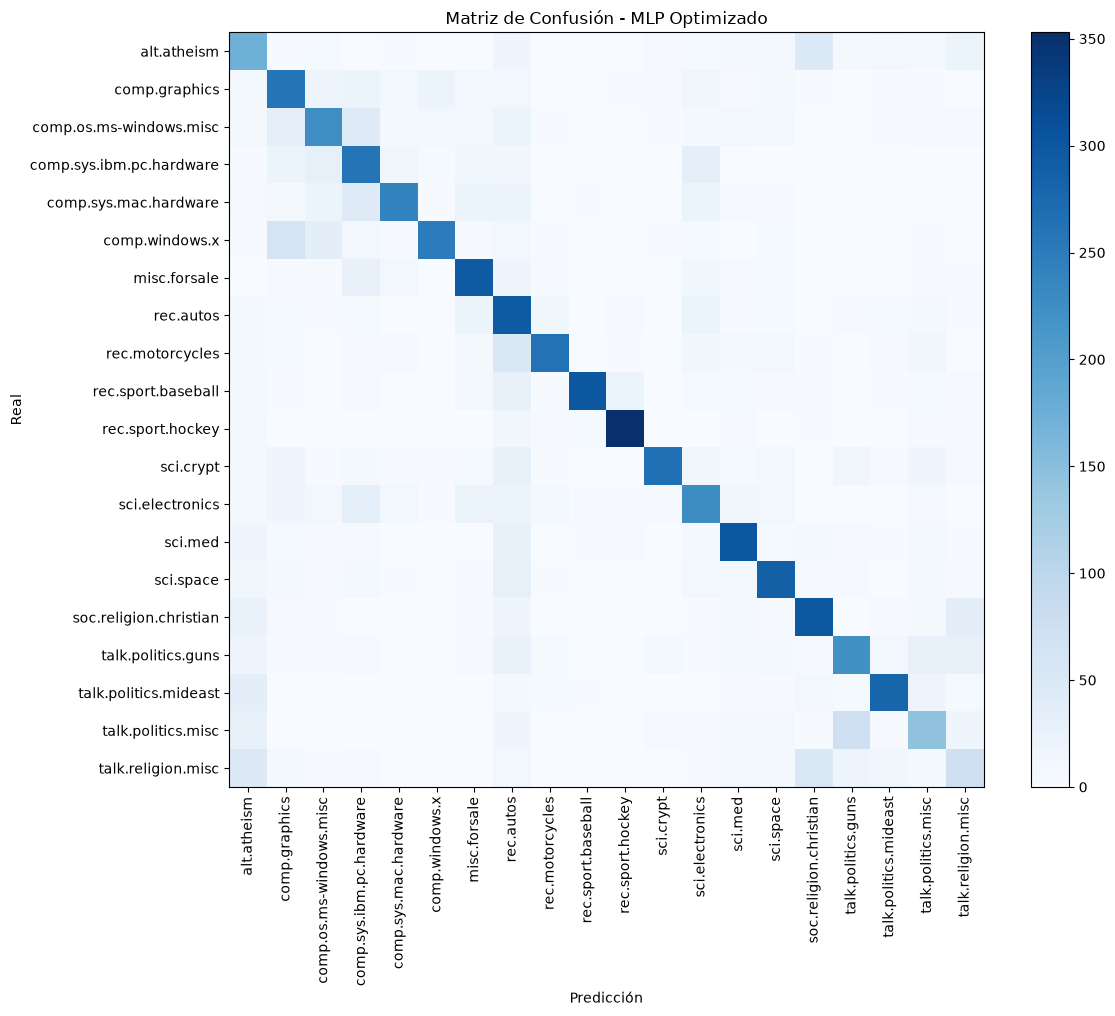

In [25]:
# Llamada para MLP
preds_mlp, labels_mlp = evaluar_y_graficar_cm(
    model=model_mlp_final, 
    test_loader=test_loader_mlp, 
    class_names=newsgroups_train.target_names, 
    model_name="MLP Optimizado",
    device=device
)

# 9. Incorporación de regularización al MLP


## 9.1 Clases y funciones 

**`MLPConfigurableReg`** agrega sobre el MLP del base: `dropout` (solo en ocultas), `batchnorm`, `weight_init='glorot'`, y la regla de que Dropout y BN no conviven en la misma capa (lanza error). Guarda `init_args` para poder reconstruir el modelo desde un `state_dict`.

**`train_model_reg`** agrega: penalización `l1`/`l2` sobre pesos, `max_norm` y  `early_stopping`.

In [ ]:
import time, copy
import numpy as np
import torch
import torch.nn as nn


# ===========================================================================
# MLPConfigurableReg 
# ===========================================================================
class MLPConfigurableReg(nn.Module):
    def __init__(self, input_dim, hidden_units, num_classes, activation_name,
                 dropout=0.0, batchnorm=False, weight_init="glorot",
                 bn_momentum=0.1, bn_eps=1e-5):
        """Misma arquitectura que MLPConfigurable del base, con regularización.

        dropout     : prob. de Dropout en capas OCULTAS (nunca en la salida).
        batchnorm   : inserta BatchNorm con orden Dense->BN->Activación (bias=False).
        weight_init : 'glorot' o 'default'.
        bn_momentum : momentum de BatchNorm1d (PyTorch 0.1 ≈ Keras 0.9).

        """
        super().__init__()
        if dropout > 0.0 and batchnorm:
            raise ValueError(
                "No se combinan Dropout y Batch Normalization en la misma capa "
                )

        # Guardamos los argumentos para poder reconstruir el modelo desde un state_dict.
        self.init_args = dict(input_dim=input_dim, hidden_units=list(hidden_units),
                              num_classes=num_classes, activation_name=activation_name,
                              dropout=dropout, batchnorm=batchnorm, weight_init=weight_init,
                              bn_momentum=bn_momentum, bn_eps=bn_eps)

        activaciones = {"sigmoid": nn.Sigmoid, "relu": nn.ReLU, "tanh": nn.Tanh,
                        "elu": nn.ELU, "leaky_relu": nn.LeakyReLU}
        act_cls = activaciones[activation_name.lower()]

        capas = []
        d_in = input_dim
        for neuronas in hidden_units:
            capas.append(nn.Linear(d_in, neuronas, bias=not batchnorm))
            if batchnorm:
                capas.append(nn.BatchNorm1d(neuronas, eps=bn_eps, momentum=bn_momentum))
            capas.append(act_cls())
            if dropout > 0.0:
                capas.append(nn.Dropout(dropout))
            d_in = neuronas
        capas.append(nn.Linear(d_in, num_classes))  

        self.red = nn.Sequential(*capas)

        if weight_init == "glorot":
            for m in self.red:
                if isinstance(m, nn.Linear):
                    nn.init.xavier_uniform_(m.weight)
                    if m.bias is not None:
                        nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.red(x)


# ===========================================================================
# Penalizaciones L1/L2 (sobre pesos, no bias) y Max-Norm
# ===========================================================================
def _reg_penalty(model, l1, l2):
    """Penalización sobre los pesos de las capas Linear. l1/l2: float (uniforme)
    o lista por capa (permite 'penalizar más las últimas capas')."""
    linears = [m for m in model.modules() if isinstance(m, nn.Linear)]

    def coef(v):
        if v is None:
            return [0.0] * len(linears)
        if isinstance(v, (list, tuple)):
            assert len(v) == len(linears), "una lambda por capa Linear"
            return list(v)
        return [float(v)] * len(linears)

    c1, c2 = coef(l1), coef(l2)
    pen = linears[0].weight.new_zeros(())
    for lin, a1, a2 in zip(linears, c1, c2):
        if a1:
            pen = pen + a1 * lin.weight.abs().sum()
        if a2:
            pen = pen + a2 * lin.weight.pow(2).sum()
    return pen


def _apply_max_norm(model, max_norm):
    """Max-Norm: ||w||_2 <= c por neurona (fila). Se aplica después de optimizer.step()."""
    if max_norm is None:
        return
    with torch.no_grad():
        for m in model.modules():
            if isinstance(m, nn.Linear):
                norm = m.weight.norm(2, dim=1, keepdim=True)
                m.weight.mul_((norm.clamp(max=max_norm)) / (norm + 1e-8))


# ===========================================================================
# train_model_reg: entrenamiento con regularización (función propia)
# ===========================================================================
def train_model_reg(model, train_loader, val_loader, optimizer, epochs,
                    writer=None, run_name="experiment", trial=None,
                    l1=0.0, l2=0.0, max_norm=None,
                    early_stopping=None, es_monitor="val_acc", restore_best=True,
                    scheduler=None, sched_monitor="val_loss",
                    log_mlflow=False, verbose=True):
    """history incluye: train_loss, val_loss, train/val_acc,
    epoch_time, lr, max_w_norm y best_epoch. Si restore_best, el modelo queda
    en su mejor época"""
    import mlflow
    try:
        import optuna
    except Exception:
        optuna = None

    model.to(device)
    criterion = nn.CrossEntropyLoss()
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [],
               "epoch_time": [], "lr": [], "max_w_norm": []}
    best_metric, best_state, best_epoch, sin_mejora = None, None, -1, 0

    for epoch in range(epochs):
        model.train()
        data_loss_sum, correct, total = 0.0, 0, 0   
        t0 = time.perf_counter()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            data_loss = criterion(logits, yb)
            loss = data_loss + (_reg_penalty(model, l1, l2) if (l1 or l2) else 0.0)
            loss.backward()
            optimizer.step()
            _apply_max_norm(model, max_norm)
            data_loss_sum += data_loss.item() * xb.size(0)   
            correct += (logits.argmax(1) == yb).sum().item()
            total += xb.size(0)
        epoch_time = time.perf_counter() - t0
        train_loss, train_acc = data_loss_sum / total, correct / total

        model.eval()
        vloss_sum, vcorrect, vtotal = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                logits = model(xb)
                vloss_sum += criterion(logits, yb).item() * xb.size(0)
                vcorrect += (logits.argmax(1) == yb).sum().item()
                vtotal += xb.size(0)
        val_loss, val_acc = vloss_sum / vtotal, vcorrect / vtotal

        with torch.no_grad():
            max_w_norm = max(m.weight.norm(2, dim=1).max().item()
                             for m in model.modules() if isinstance(m, nn.Linear))

        for k, v in [("train_loss", train_loss), ("val_loss", val_loss),
                     ("train_acc", train_acc), ("val_acc", val_acc),
                     ("epoch_time", epoch_time),
                     ("lr", optimizer.param_groups[0]["lr"]), ("max_w_norm", max_w_norm)]:
            history[k].append(v)

        if verbose:
            print(f"[{run_name}] {epoch+1}/{epochs} tr_acc={train_acc:.4f} "
                  f"val_acc={val_acc:.4f} val_loss={val_loss:.4f} "
                  f"|w|max={max_w_norm:.2f} {epoch_time:.2f}s")
        if writer is not None:
            writer.add_scalars("loss", {"train": train_loss, "val": val_loss}, epoch)
            writer.add_scalars("accuracy", {"train": train_acc, "val": val_acc}, epoch)
        if log_mlflow:
            mlflow.log_metric("train_loss", train_loss, step=epoch)
            mlflow.log_metric("val_loss", val_loss, step=epoch)
            mlflow.log_metric("train_acc", train_acc, step=epoch)
            mlflow.log_metric("val_acc", val_acc, step=epoch)
        if scheduler is not None:
            scheduler.step(val_loss if sched_monitor == "val_loss" else val_acc)

        # seguimiento de la MEJOR época 
        metrica = val_loss if es_monitor == "val_loss" else val_acc
        mejor = (best_metric is None or
                 (metrica < best_metric if es_monitor == "val_loss" else metrica > best_metric))
        if mejor:
            best_metric, best_epoch, sin_mejora = metrica, epoch, 0
            if restore_best:
                best_state = copy.deepcopy(model.state_dict())
        else:
            sin_mejora += 1

        if trial is not None and optuna is not None:
            trial.report(val_acc, step=epoch)
            if trial.should_prune():
                raise optuna.exceptions.TrialPruned()

        if early_stopping is not None and sin_mejora >= early_stopping:
            if verbose:
                print(f"[{run_name}] early stopping en época {epoch+1} "
                      f"(mejor={best_epoch+1}, {es_monitor}={best_metric:.4f})")
            break

    if restore_best and best_state is not None:
        model.load_state_dict(best_state)  
    history["best_epoch"] = best_epoch
    return history


# ===========================================================================
# Cosas para el análisis
# ===========================================================================
def weight_stats(model, zero_tol=1e-6):
    w = torch.cat([m.weight.detach().flatten()
                   for m in model.modules() if isinstance(m, nn.Linear)])
    aw = w.abs()
    return {"mean_abs": aw.mean().item(), "max_abs": aw.max().item(),
            "frac_zero": (aw < zero_tol).float().mean().item(), "n_params": w.numel()}


def eval_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            correct += (model(xb.to(device)).argmax(1).cpu() == yb).sum().item()
            total += yb.size(0)
    return correct / total


def prune_and_eval(model, loader, thresholds):
    """Poda: lleva a 0 los pesos con |w|<umbral y mide accuracy + % activos."""
    base_state = copy.deepcopy(model.state_dict())
    filas = []
    for thr in thresholds:
        m = copy.deepcopy(model)
        m.load_state_dict(base_state)
        total, activos = 0, 0
        with torch.no_grad():
            for mod in m.modules():
                if isinstance(mod, nn.Linear):
                    mask = mod.weight.abs() >= thr
                    mod.weight.mul_(mask)
                    total += mask.numel()
                    activos += mask.sum().item()
        filas.append({"umbral": thr, "acc_val": eval_accuracy(m, loader),
                      "pct_activos": 100.0 * activos / total, "n_activos": activos})
    return filas


## 9.2 Configuración de experimentos común (baseline y datos)

Para que las comparaciones sean univariadas, todos los experimentos comparten exactamente la misma configuración, y solo se modifica la técnica de regularización que se esté evaluando:

- Preprocesamiento fijo: `remove_stopwords=True`, `normalization="none"`, `ngram=(1,1)`, `max_features=5000`, `min_df=2`, fijo e independiente de la búsqueda de Optuna, para que lo único que varíe sea la regularización.
- Arquitectura fija: 2 capas ocultas `[512, 256]`, ReLU, salida de 20 clases, inicialización Glorot.
- Entrenamiento fijo: Adam, `lr=1e-3`, `batch_size=128`, 30 épocas de base.
- Datos: split train/validación 80/20 estratificado (semilla fija). El vectorizador TF-IDF se ajusta solo con el 80 % de train.

Se reutilizan de antes: `vectorize_data`, `to_tensor_dataset`, `preprocessed_cache`, `NUM_CLASSES`, `class_names` y `device` ya definidos arriba.

In [ ]:
import time
import pandas as pd


REG_SEED   = SEED          # SEED = 42
REG_PRE    = (True, "none")  # (remove_stopwords, normalization)
REG_NGRAM  = (1, 1)
REG_MAXF   = 5000
REG_MINDF  = 2
REG_HIDDEN = [512, 256]
REG_ACT    = "relu"
REG_INIT   = "glorot"
REG_LR     = 1e-3
REG_BATCH  = 128
REG_EPOCHS = 30


reg_train_texts, reg_test_texts = preprocessed_cache[REG_PRE]
_y = np.array(newsgroups_train.target)
reg_idx_tr, reg_idx_va = train_test_split(
    np.arange(len(_y)), test_size=0.2, stratify=_y, random_state=REG_SEED)

X_tr_reg, X_va_reg, reg_vectorizer = vectorize_data(
    [reg_train_texts[i] for i in reg_idx_tr],
    [reg_train_texts[i] for i in reg_idx_va],
    REG_NGRAM, REG_MAXF, REG_MINDF)

# Generador propio: aísla el shuffle del estado global del RNG (reproducible sin importar el orden de celdas)
g_reg = torch.Generator().manual_seed(REG_SEED)
reg_train_loader = DataLoader(to_tensor_dataset(X_tr_reg, _y[reg_idx_tr]),
                              batch_size=REG_BATCH, shuffle=True, generator=g_reg)
reg_val_loader = DataLoader(to_tensor_dataset(X_va_reg, _y[reg_idx_va]),
                            batch_size=REG_BATCH, shuffle=False)
REG_INPUT_DIM = X_tr_reg.shape[1]
print("Datos de regularización ->", X_tr_reg.shape, X_va_reg.shape, "| features:", REG_INPUT_DIM)


def build_reg_mlp(dropout=0.0, batchnorm=False):
    """Construye el MLP baseline con la semilla fija."""
    torch.manual_seed(REG_SEED)
    return MLPConfigurableReg(REG_INPUT_DIM, REG_HIDDEN, NUM_CLASSES, REG_ACT,
                              dropout=dropout, batchnorm=batchnorm, weight_init=REG_INIT)


def make_adam(model, lr=REG_LR):
    return optim.Adam(model.parameters(), lr=lr)


resultados_reg = {}  # nombre -> métricas e historia del experimento


def run_reg(nombre, model, optimizer=None, epochs=REG_EPOCHS, **tkw):
    """Entrena un experimento y guarda resultados. El modelo queda en su MEJOR época
    (restore_best) y TODAS las métricas se reportan en esa época.
    """
    if optimizer is None:
        optimizer = make_adam(model)
    g_reg.manual_seed(REG_SEED)            
    tkw.setdefault("restore_best", True)
    hist = train_model_reg(model, reg_train_loader, reg_val_loader, optimizer,
                           epochs=epochs, run_name=nombre, log_mlflow=False,
                           verbose=True, **tkw)
    be = hist["best_epoch"]
    st = weight_stats(model)
    resultados_reg[nombre] = {
        "history": hist, "weight_stats": st, "model": model, "best_epoch": be,
        "val_acc": hist["val_acc"][be], "train_acc": hist["train_acc"][be],
        "val_loss": hist["val_loss"][be],
        "brecha_train_val": hist["train_acc"][be] - hist["val_acc"][be],
        "t_ep_mean": float(np.mean(hist["epoch_time"])),
        "max_w_norm": max(hist["max_w_norm"]),
        "epocas": len(hist["val_acc"]),
    }
    print(f">> {nombre}: val_acc(best ep {be+1})={hist['val_acc'][be]:.4f} | "
          f"train_acc={hist['train_acc'][be]:.4f} | "
          f"brecha={hist['train_acc'][be]-hist['val_acc'][be]:.4f} | "
          f"mean|w|={st['mean_abs']:.4f} | |w|max={max(hist['max_w_norm']):.2f} | "
          f"t/ep={np.mean(hist['epoch_time']):.2f}s")
    return hist


Datos de regularización -> (9051, 5000) (2263, 5000) | features: 5000


## 9.3 Experimento 0: sin regularización

Primero entrenamos la red sin ninguna técnica de regularización, para tener algo con qué comparar. Es una red grande, con muchos parámetros, y las redes grandes tienden a memorizar los datos de entrenamiento, incluso el ruido (sobreajuste).

La idea es ver cuánto se separa la accuracy de train de la de validación (la brecha), qué tan grandes quedan los pesos cuando nadie los limita, cuánto tarda cada época y cómo se ven las curvas. Después comparamos cada técnica de los experimentos siguientes contra este resultado.

In [31]:
run_reg("Exp0_baseline", build_reg_mlp());

[Exp0_baseline] 1/30 tr_acc=0.4417 val_acc=0.6483 val_loss=1.3192 |w|max=1.92 1.94s
[Exp0_baseline] 2/30 tr_acc=0.7798 val_acc=0.6765 val_loss=1.0667 |w|max=2.25 1.59s
[Exp0_baseline] 3/30 tr_acc=0.9020 val_acc=0.6810 val_loss=1.0658 |w|max=2.45 1.50s
[Exp0_baseline] 4/30 tr_acc=0.9501 val_acc=0.6805 val_loss=1.1342 |w|max=2.62 2.05s
[Exp0_baseline] 5/30 tr_acc=0.9656 val_acc=0.6757 val_loss=1.2185 |w|max=2.73 2.14s
[Exp0_baseline] 6/30 tr_acc=0.9704 val_acc=0.6726 val_loss=1.2809 |w|max=2.81 2.06s
[Exp0_baseline] 7/30 tr_acc=0.9701 val_acc=0.6686 val_loss=1.3366 |w|max=2.86 1.93s
[Exp0_baseline] 8/30 tr_acc=0.9707 val_acc=0.6620 val_loss=1.3993 |w|max=2.91 1.76s
[Exp0_baseline] 9/30 tr_acc=0.9707 val_acc=0.6673 val_loss=1.4273 |w|max=2.95 1.97s
[Exp0_baseline] 10/30 tr_acc=0.9703 val_acc=0.6690 val_loss=1.4387 |w|max=2.99 1.97s
[Exp0_baseline] 11/30 tr_acc=0.9702 val_acc=0.6628 val_loss=1.4708 |w|max=3.02 1.94s
[Exp0_baseline] 12/30 tr_acc=0.9706 val_acc=0.6633 val_loss=1.5123 |w|max=

## 9.4 Experimento 1: Regularización L2 (Weight Decay)

L2 le suma a la Loss un castigo por tener pesos grandes: $\lambda\sum_i w_i^2$. Al actualizar, cada peso se multiplica por un factor un poco menor que 1, $(1-2\eta\lambda)$, antes de aplicar el gradiente, y por eso se la llama *weight decay* (decaimiento de pesos). Esa contracción es más fuerte cuando el peso es grande y casi nula cuando ya es chico, así que los pesos se achican de forma suave pero nunca llegan a ser exactamente cero. En conjunto, la distribución de pesos se va comprimiendo hacia el origen.

Se implementó sumando la penalización a mano sobre los pesos de las capas `Linear` (parámetro `l2` de `train_model_reg`). No se penaliza el bias porque solo desplaza la activación y no aporta complejidad al modelo.

Se usó $\lambda = 10^{-5}$, $10^{-4}$ y $10^{-3}$ y una variante donde $\lambda$ crece hacia las capas cercanas a la salida. Todo lo demás queda igual que en el base, para que cualquier diferencia se deba a L2.

Se espera que al subir $\lambda$ bajen `mean(|w|)` y `max(|w|)`, que se achique la brecha entre train y validación, y que con un $\lambda$ demasiado alto el modelo empiece a subajustar.



In [32]:
for lam in [1e-5, 1e-4, 1e-3]:
    run_reg(f"Exp1_L2_{lam:.0e}", build_reg_mlp(), l2=lam)

# Variante por capa: mayor lambda en las capas cercanas a la salida [oculta1, oculta2, salida]
run_reg("Exp1_L2_porcapa", build_reg_mlp(), l2=[1e-4, 2e-4, 4e-4]);

[Exp1_L2_1e-05] 1/30 tr_acc=0.4479 val_acc=0.6522 val_loss=1.3125 |w|max=1.87 3.18s
[Exp1_L2_1e-05] 2/30 tr_acc=0.7811 val_acc=0.6792 val_loss=1.0665 |w|max=2.09 2.63s
[Exp1_L2_1e-05] 3/30 tr_acc=0.9027 val_acc=0.6792 val_loss=1.0675 |w|max=2.26 3.01s
[Exp1_L2_1e-05] 4/30 tr_acc=0.9501 val_acc=0.6787 val_loss=1.1333 |w|max=2.42 2.65s
[Exp1_L2_1e-05] 5/30 tr_acc=0.9653 val_acc=0.6721 val_loss=1.2133 |w|max=2.50 2.67s
[Exp1_L2_1e-05] 6/30 tr_acc=0.9705 val_acc=0.6712 val_loss=1.2697 |w|max=2.54 2.84s
[Exp1_L2_1e-05] 7/30 tr_acc=0.9701 val_acc=0.6624 val_loss=1.3227 |w|max=2.56 3.06s
[Exp1_L2_1e-05] 8/30 tr_acc=0.9704 val_acc=0.6664 val_loss=1.3752 |w|max=2.56 2.79s
[Exp1_L2_1e-05] 9/30 tr_acc=0.9711 val_acc=0.6615 val_loss=1.3974 |w|max=2.56 2.58s
[Exp1_L2_1e-05] 10/30 tr_acc=0.9705 val_acc=0.6620 val_loss=1.4058 |w|max=2.55 2.60s
[Exp1_L2_1e-05] 11/30 tr_acc=0.9702 val_acc=0.6558 val_loss=1.4271 |w|max=2.53 2.58s
[Exp1_L2_1e-05] 12/30 tr_acc=0.9709 val_acc=0.6567 val_loss=1.4581 |w|max=


**Qué vimos.** Con $\lambda=10^{-3}$ los pesos se achicaron claramente: `mean|w|` bajó de 0,028 en el baseline a 0,0106, y la brecha entre train y validación en la época 3 pasó de 0,22 (0,9020 − 0,681) en el baseline a 0,095. Con $\lambda=10^{-5}$ y $10^{-4}$ casi no hubo diferencia con el baseline (brecha de 0,22 en la época 3). Con $10^{-3}$ la accuracy de validación fue algo menor (0,659 contra 0,681), señal de que ya empieza a restringir demasiado. En ninguna configuración L2 mejoró la validación respecto del baseline.

## 9.5 Experimento 2: Regularización L1 y Poda 

L1 penaliza la suma de los valores absolutos de los pesos, $\lambda\sum_i|w_i|$. A diferencia de L2, el empujón hacia cero tiene siempre el mismo tamaño ($\pm\lambda$), sin importar si el peso es grande o chico, por eso los pesos poco importantes terminan casi en cero y quedan pocas conexiones que realmente cuentan. Ae puso en cero los pesos menores a un umbral y se midió cuánta accuracy de validación se mantiene.

Se probó $\lambda = 10^{-6}$, $10^{-5}$ y $10^{-4}$, y después se barrieron umbrales de poda sobre el mejor modelo según validación.



In [33]:
for lam in [1e-6, 1e-5, 1e-4]:
    run_reg(f"Exp2_L1_{lam:.0e}", build_reg_mlp(), l1=lam)

# Poda sobre el mejor modelo L1 (por val_acc)
cand_l1 = {k: v for k, v in resultados_reg.items() if k.startswith("Exp2_L1")}
mejor_l1_nombre = max(cand_l1, key=lambda k: cand_l1[k]["val_acc"])
print("Mejor L1:", mejor_l1_nombre)
tabla_prune = prune_and_eval(resultados_reg[mejor_l1_nombre]["model"], reg_val_loader,
                             thresholds=[0.0, 1e-3, 5e-3, 1e-2, 2e-2, 5e-2, 1e-1])
df_prune = pd.DataFrame(tabla_prune)
print(df_prune.to_string(index=False))

[Exp2_L1_1e-06] 1/30 tr_acc=0.4458 val_acc=0.6518 val_loss=1.3129 |w|max=1.88 2.51s
[Exp2_L1_1e-06] 2/30 tr_acc=0.7801 val_acc=0.6779 val_loss=1.0678 |w|max=2.10 2.40s
[Exp2_L1_1e-06] 3/30 tr_acc=0.9020 val_acc=0.6779 val_loss=1.0676 |w|max=2.22 2.38s
[Exp2_L1_1e-06] 4/30 tr_acc=0.9494 val_acc=0.6801 val_loss=1.1335 |w|max=2.35 2.24s
[Exp2_L1_1e-06] 5/30 tr_acc=0.9649 val_acc=0.6686 val_loss=1.2132 |w|max=2.43 2.00s
[Exp2_L1_1e-06] 6/30 tr_acc=0.9703 val_acc=0.6726 val_loss=1.2708 |w|max=2.47 2.07s
[Exp2_L1_1e-06] 7/30 tr_acc=0.9701 val_acc=0.6642 val_loss=1.3248 |w|max=2.48 2.29s
[Exp2_L1_1e-06] 8/30 tr_acc=0.9704 val_acc=0.6615 val_loss=1.3800 |w|max=2.48 3.17s
[Exp2_L1_1e-06] 9/30 tr_acc=0.9711 val_acc=0.6628 val_loss=1.4030 |w|max=2.49 2.05s
[Exp2_L1_1e-06] 10/30 tr_acc=0.9705 val_acc=0.6620 val_loss=1.4126 |w|max=2.51 2.08s
[Exp2_L1_1e-06] 11/30 tr_acc=0.9702 val_acc=0.6580 val_loss=1.4346 |w|max=2.54 2.20s
[Exp2_L1_1e-06] 12/30 tr_acc=0.9712 val_acc=0.6567 val_loss=1.4667 |w|max=

Con $\lambda=10^{-4}$ los pesos bajaron mucho (`mean|w|` de 0,028 a 0,0026), y el `max|w|` subió a 0,79, lo que indica que unos pocos pesos concentran la masa y el resto queda cerca de cero. Con esa $\lambda$ el modelo subajusta (validación 0,635). En la poda, con un umbral de 0,02 se conserva solo el 50 % de las conexiones sin perder accuracy (0,684 contra 0,680). Con 0,05 queda el 12,5 % y la accuracy baja a 0,658, y con 0,1 queda el 1,3 % y colapsa a 0,17. Hay que aclarar que la poda se hizo sobre el modelo con $\lambda=10^{-6}$, que fue el mejor en validación y casi no está regularizado.

## 9.6 Experimento 3: L1 + L2 

Se combinan las dos penalizaciones, $\lambda_1\sum|w_i|+\lambda_2\sum w_i^2$, para juntar la eliminación de conexiones de L1 con la contracción suave de L2. 


In [34]:
run_reg("Exp3_L1L2", build_reg_mlp(), l1=1e-5, l2=1e-4);

[Exp3_L1L2] 1/30 tr_acc=0.4148 val_acc=0.6284 val_loss=1.4422 |w|max=1.80 2.48s
[Exp3_L1L2] 2/30 tr_acc=0.7367 val_acc=0.6717 val_loss=1.1195 |w|max=2.08 2.56s
[Exp3_L1L2] 3/30 tr_acc=0.8528 val_acc=0.6668 val_loss=1.0988 |w|max=2.27 2.64s
[Exp3_L1L2] 4/30 tr_acc=0.9083 val_acc=0.6659 val_loss=1.1246 |w|max=2.42 2.44s
[Exp3_L1L2] 5/30 tr_acc=0.9406 val_acc=0.6628 val_loss=1.1682 |w|max=2.53 2.39s
[Exp3_L1L2] 6/30 tr_acc=0.9564 val_acc=0.6615 val_loss=1.2078 |w|max=2.65 2.54s
[Exp3_L1L2] 7/30 tr_acc=0.9610 val_acc=0.6513 val_loss=1.2416 |w|max=2.75 2.36s
[Exp3_L1L2] 8/30 tr_acc=0.9632 val_acc=0.6452 val_loss=1.2721 |w|max=2.85 2.35s
[Exp3_L1L2] 9/30 tr_acc=0.9653 val_acc=0.6399 val_loss=1.3012 |w|max=2.93 2.32s
[Exp3_L1L2] 10/30 tr_acc=0.9669 val_acc=0.6403 val_loss=1.3168 |w|max=3.02 2.34s
[Exp3_L1L2] 11/30 tr_acc=0.9659 val_acc=0.6452 val_loss=1.3182 |w|max=3.09 2.33s
[Exp3_L1L2] 12/30 tr_acc=0.9667 val_acc=0.6474 val_loss=1.3427 |w|max=3.16 2.42s
[Exp3_L1L2] 13/30 tr_acc=0.9670 val_a

Los pesos se achicaron (`mean|w|` de 0,013 contra 0,028) y la brecha en la época 3 fue algo menor (0,19 contra 0,22), pero la validación no mejoró (0,672 contra 0,681). Combinarlas no aportó más que usarlas por separado.

## 9.7 Experimento 4: Dropout

En cada paso de entrenamiento, Dropout apaga al azar una fracción $p$ de las neuronas. Así la red no puede depender de que dos neuronas se corrijan entre sí (co-adaptaciones), y es como entrenar muchas sub-redes a la vez. En entrenamiento se reescalan las activaciones que quedan por $1/(1-p)$ y en evaluación se usa la red completa. Por eso se esperan curvas de train con mucho ruido y, al principio, la validación por encima de train, porque en train se mide una red recortada.

Lo puse con `nn.Dropout` en las capas ocultas, nunca en la salida ni en la entrada. Probé $p = 0{,}2$, $0{,}3$ y $0{,}5$ con hasta 80 épocas y early stopping con patience 15. Como el baseline usa Adam, mantuve Adam para que la comparación fuera justa.


In [35]:
REG_EPOCHS_DROP = 80
for p in [0.2, 0.3, 0.5]:
    run_reg(f"Exp4_Dropout_{p}", build_reg_mlp(dropout=p),
            epochs=REG_EPOCHS_DROP, early_stopping=15, es_monitor="val_acc")

# Exp4b: receta LITERAL del profesor para Dropout (SGD, LR x10, momentum 0.9)
m4b = build_reg_mlp(dropout=0.3)
opt4b = optim.SGD(m4b.parameters(), lr=REG_LR * 10, momentum=0.9)
run_reg("Exp4b_Dropout_SGD_LRx10", m4b, optimizer=opt4b,
        epochs=REG_EPOCHS_DROP, early_stopping=15, es_monitor="val_acc");

[Exp4_Dropout_0.2] 1/80 tr_acc=0.3674 val_acc=0.6372 val_loss=1.4807 |w|max=1.87 1.97s
[Exp4_Dropout_0.2] 2/80 tr_acc=0.7286 val_acc=0.6792 val_loss=1.0675 |w|max=2.14 2.22s
[Exp4_Dropout_0.2] 3/80 tr_acc=0.8597 val_acc=0.6947 val_loss=1.0383 |w|max=2.37 2.09s
[Exp4_Dropout_0.2] 4/80 tr_acc=0.9239 val_acc=0.6880 val_loss=1.0839 |w|max=2.55 1.81s
[Exp4_Dropout_0.2] 5/80 tr_acc=0.9508 val_acc=0.6774 val_loss=1.1636 |w|max=2.69 1.94s
[Exp4_Dropout_0.2] 6/80 tr_acc=0.9625 val_acc=0.6770 val_loss=1.2250 |w|max=2.78 2.00s
[Exp4_Dropout_0.2] 7/80 tr_acc=0.9667 val_acc=0.6717 val_loss=1.2865 |w|max=2.84 2.22s
[Exp4_Dropout_0.2] 8/80 tr_acc=0.9699 val_acc=0.6717 val_loss=1.3451 |w|max=2.90 2.23s
[Exp4_Dropout_0.2] 9/80 tr_acc=0.9690 val_acc=0.6699 val_loss=1.3802 |w|max=2.95 2.32s
[Exp4_Dropout_0.2] 10/80 tr_acc=0.9694 val_acc=0.6690 val_loss=1.4068 |w|max=3.01 1.94s
[Exp4_Dropout_0.2] 11/80 tr_acc=0.9693 val_acc=0.6681 val_loss=1.4412 |w|max=3.05 1.77s
[Exp4_Dropout_0.2] 12/80 tr_acc=0.9707 va

A igual época la brecha baja al subir $p$: en la época 3 es 0,22 en el baseline y 0,165, 0,134 y 0,066 con $p$ = 0,2, 0,3 y 0,5. Dropout también retrasa el ajuste del train (95 % en la época 5, 6 y 9 contra la 4 del baseline), y al comienzo la validación supera a train (con $p=0{,}2$, en la época 1: train 0,37 y validación 0,64). La validación mejora levemente (0,692 a 0,696 contra 0,681), aunque con una sola semilla una diferencia de ~1,5 puntos no es concluyente. Con Adam el early stopping cortó en la época 18, con mejor época 3, así que las épocas extra no se aprovecharon. En el Exp4b (SGD, lr ×10, momentum 0,9) la convergencia fue lenta, con mejor época 57, y la validación quedó en 0,684.


## 9.8 Experimento 5:Batch Normalization

Batch Normalization normaliza las activaciones de cada mini-batch (resta la media y divide por el desvío) y después las reescala con dos parámetros que se aprenden, $\gamma$ y $\beta$. Se propuso para reducir el *internal covariate shift* y acelerar el entrenamiento, y que además regularice es un efecto secundario, por el ruido que aporta cada mini-batch. En evaluación usa promedios acumulados durante el entrenamiento.

Se usó el orden Linear → BatchNorm → Activación, sin bias en la `Linear` anterior (el $\beta$ ya cumple ese rol), $\epsilon=10^{-5}$ y `momentum=0,1` de PyTorch, y no se combinó con Dropout. 



In [36]:
run_reg("Exp5_BatchNorm", build_reg_mlp(batchnorm=True))

# Exp5b: BN permite típicamente learning rates más altos
m5b = build_reg_mlp(batchnorm=True)
run_reg("Exp5b_BN_LRx5", m5b, optimizer=make_adam(m5b, lr=REG_LR * 5));

[Exp5_BatchNorm] 1/30 tr_acc=0.5456 val_acc=0.6465 val_loss=1.2491 |w|max=1.50 2.02s
[Exp5_BatchNorm] 2/30 tr_acc=0.9544 val_acc=0.6611 val_loss=1.1581 |w|max=1.54 1.77s
[Exp5_BatchNorm] 3/30 tr_acc=0.9693 val_acc=0.6606 val_loss=1.1880 |w|max=1.58 1.72s
[Exp5_BatchNorm] 4/30 tr_acc=0.9708 val_acc=0.6646 val_loss=1.1929 |w|max=1.61 1.76s
[Exp5_BatchNorm] 5/30 tr_acc=0.9713 val_acc=0.6664 val_loss=1.2109 |w|max=1.62 1.64s
[Exp5_BatchNorm] 6/30 tr_acc=0.9711 val_acc=0.6606 val_loss=1.2202 |w|max=1.64 1.68s
[Exp5_BatchNorm] 7/30 tr_acc=0.9711 val_acc=0.6664 val_loss=1.2285 |w|max=1.65 1.87s
[Exp5_BatchNorm] 8/30 tr_acc=0.9711 val_acc=0.6655 val_loss=1.2364 |w|max=1.66 2.03s
[Exp5_BatchNorm] 9/30 tr_acc=0.9706 val_acc=0.6642 val_loss=1.2458 |w|max=1.68 1.92s
[Exp5_BatchNorm] 10/30 tr_acc=0.9707 val_acc=0.6668 val_loss=1.2531 |w|max=1.69 1.74s
[Exp5_BatchNorm] 11/30 tr_acc=0.9712 val_acc=0.6668 val_loss=1.2584 |w|max=1.69 1.62s
[Exp5_BatchNorm] 12/30 tr_acc=0.9709 val_acc=0.6646 val_loss=1.

Se esperaba que convergiera en menos épocas, que cada época tardara un poco más y que las curvas fueran más suaves. Llegó a 95 % de accuracy de train en la época 2, contra la 4 del baseline, y mantuvo la norma máxima de fila de los pesos en 1,81 contra 3,51. Pero no mejoró la validación (0,671 contra 0,681) y tuvo la mayor brecha (0,31 en la época 3), o sea que acelera pero no regulariza en una red de solo dos capas. Con el learning rate ×5 la validación tampoco mejoró (0,666) y la val_loss mínima apareció ya en la época 1, es decir que un lr más alto acelera el sobreajuste. El tiempo por época no se distingue del ruido de medición.

## 9.9 Experimento 6: "Receta ganadora" vista en clase

Combinación recomendada para máxima estabilidad: **Dropout + Max-Norm (c=4–5) + Early Stopping + ReduceLROnPlateau**. Max-Norm acota $\|w\|_2\le c$ por neurona (reproyección tras cada paso); Early Stopping corta en el óptimo de validación; el scheduler baja el LR al estancarse.

**Implementación.** `dropout=0.3`, `max_norm=4.0`, `early_stopping=15`, `ReduceLROnPlateau(factor=0.1, patience=5, min_lr=1e-5)` sobre `val_loss`. Épocas altas (80): Early Stopping decide el corte.


In [37]:
m6 = build_reg_mlp(dropout=0.3)
opt6 = optim.Adam(m6.parameters(), lr=REG_LR)
sched6 = optim.lr_scheduler.ReduceLROnPlateau(opt6, mode="min", factor=0.1,
                                              patience=5, min_lr=1e-5)
run_reg("Exp6_receta", m6, optimizer=opt6, epochs=80, max_norm=4.0,
        early_stopping=15, es_monitor="val_loss",
        scheduler=sched6, sched_monitor="val_loss");

[Exp6_receta] 1/80 tr_acc=0.3312 val_acc=0.6240 val_loss=1.6173 |w|max=1.84 2.02s
[Exp6_receta] 2/80 tr_acc=0.6955 val_acc=0.6770 val_loss=1.0809 |w|max=2.11 2.06s
[Exp6_receta] 3/80 tr_acc=0.8295 val_acc=0.6960 val_loss=1.0253 |w|max=2.37 2.01s
[Exp6_receta] 4/80 tr_acc=0.9055 val_acc=0.6876 val_loss=1.0586 |w|max=2.55 1.97s
[Exp6_receta] 5/80 tr_acc=0.9383 val_acc=0.6827 val_loss=1.1244 |w|max=2.69 1.93s
[Exp6_receta] 6/80 tr_acc=0.9553 val_acc=0.6863 val_loss=1.1858 |w|max=2.80 1.74s
[Exp6_receta] 7/80 tr_acc=0.9623 val_acc=0.6717 val_loss=1.2535 |w|max=2.87 1.75s
[Exp6_receta] 8/80 tr_acc=0.9675 val_acc=0.6734 val_loss=1.3005 |w|max=2.94 1.84s
[Exp6_receta] 9/80 tr_acc=0.9672 val_acc=0.6686 val_loss=1.3469 |w|max=2.99 1.75s
[Exp6_receta] 10/80 tr_acc=0.9696 val_acc=0.6717 val_loss=1.3433 |w|max=2.99 1.78s
[Exp6_receta] 11/80 tr_acc=0.9702 val_acc=0.6717 val_loss=1.3449 |w|max=3.00 1.77s
[Exp6_receta] 12/80 tr_acc=0.9703 val_acc=0.6708 val_loss=1.3508 |w|max=3.00 1.71s
[Exp6_receta]

## 9.10 Comparación 

Se consolidan los resultados en una tabla y en gráficos que cubren los cuatro aspectod marcados en la consigna: magnitud de pesos, tiempos, learning rate y curvas de aprendizaje. Las métricas se reportan en la mejor época de cada experimento.

In [ ]:
# ----- Tabla comparativa -----
filas = []
for nombre, r in resultados_reg.items():
    filas.append({
        "experimento": nombre,
        "val_acc": round(r["val_acc"], 4),
        "train_acc": round(r["train_acc"], 4),
        "brecha_train_val": round(r["brecha_train_val"], 4),
        "mean_abs_w": round(r["weight_stats"]["mean_abs"], 5),
        "max_abs_w": round(r["weight_stats"]["max_abs"], 3),
        "max_w_norm_fila": round(r["max_w_norm"], 3),   
        "frac_zero_w": round(r["weight_stats"]["frac_zero"], 4),
        "t_ep_mean_s": round(r["t_ep_mean"], 3),
        "epocas": r["epocas"],
        "mejor_epoca": r["best_epoch"] + 1,
    })
tabla_reg = pd.DataFrame(filas).set_index("experimento")
tabla_reg

,val_acc,train_acc,brecha_train_val,mean_abs_w,max_abs_w,max_w_norm_fila,frac_zero_w,t_ep_mean_s,epocas,mejor_epoca
experimento,,,,,,,,,,
Exp0_baseline,0.6810,0.9020,0.2210,0.02808,0.275,3.506,0.0000,2.374,30,3
Exp1_L2_1e-05,0.6792,0.7811,0.1019,0.02360,0.253,2.926,0.0000,2.650,30,2
Exp1_L2_1e-04,0.6765,0.7709,0.0943,0.01951,0.255,3.750,0.0001,2.579,30,2
Exp1_L2_1e-03,0.6589,0.8430,0.1841,0.01065,0.363,3.474,0.0078,2.621,30,6
Exp1_L2_porcapa,0.6783,0.7616,0.0833,0.01942,0.249,3.080,0.0001,2.379,30,2
Exp2_L1_1e-06,0.6801,0.9494,0.2693,0.02558,0.286,3.008,0.0005,2.046,30,4
Exp2_L1_1e-05,0.6783,0.7532,0.0749,0.01469,0.261,3.928,0.0002,1.933,30,2
Exp2_L1_1e-04,0.6354,0.8444,0.2090,0.00264,0.788,5.489,0.0065,1.872,30,12
Exp3_L1L2,0.6717,0.7367,0.0650,0.01325,0.263,4.252,0.0003,2.560,30,2


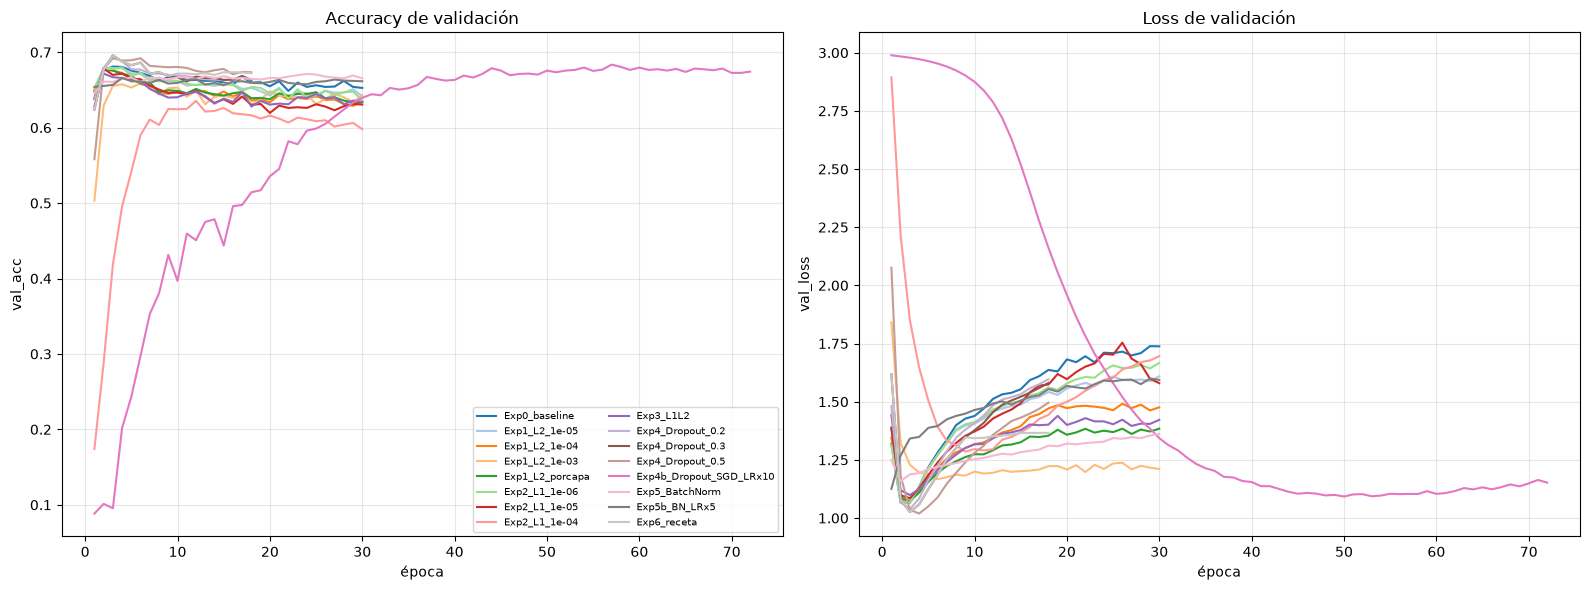

In [39]:
# ----- Curvas de aprendizaje (val_acc y val_loss por experimento) -----
cmap = plt.get_cmap("tab20")
colores = {n: cmap(i % 20) for i, n in enumerate(resultados_reg)}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for nombre, r in resultados_reg.items():
    h = r["history"]; ep = range(1, len(h["val_acc"]) + 1)
    axes[0].plot(ep, h["val_acc"], label=nombre, color=colores[nombre])
    axes[1].plot(ep, h["val_loss"], label=nombre, color=colores[nombre])
axes[0].set_title("Accuracy de validación"); axes[0].set_xlabel("época"); axes[0].set_ylabel("val_acc")
axes[1].set_title("Loss de validación"); axes[1].set_xlabel("época"); axes[1].set_ylabel("val_loss")
axes[0].legend(fontsize=7, ncol=2); axes[0].grid(alpha=.3); axes[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

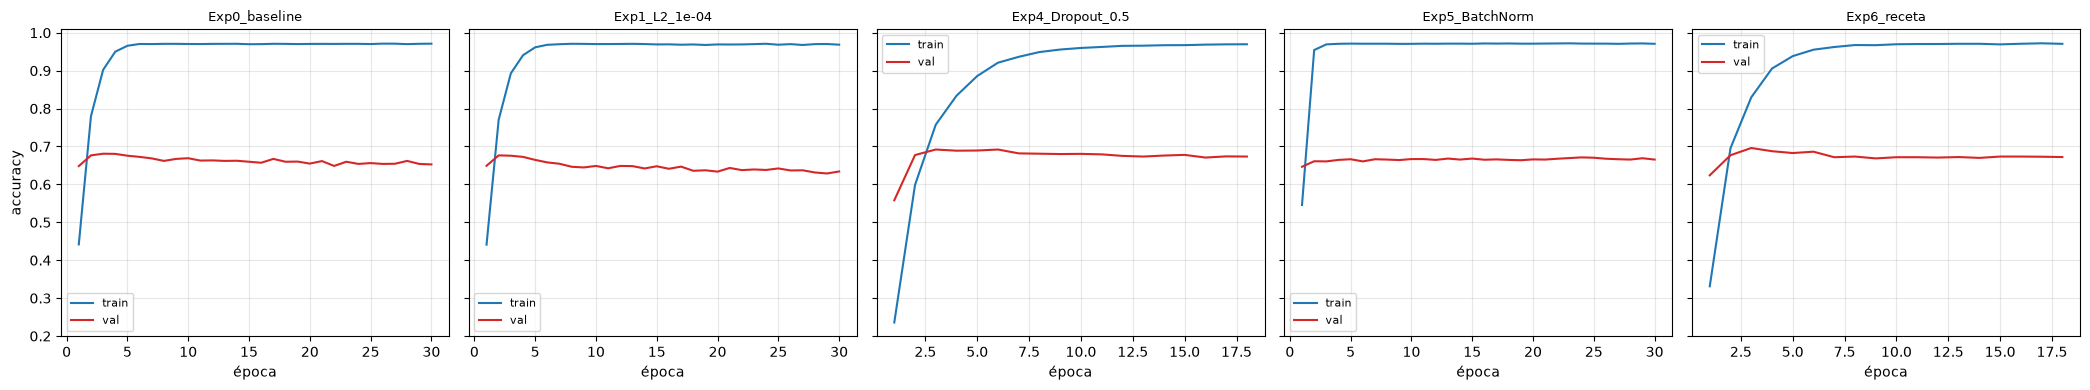

In [40]:
# ----- Train vs Val (diagnóstico de overfitting / ruido) -----
focos = [n for n in ["Exp0_baseline", "Exp1_L2_1e-04", "Exp4_Dropout_0.5", "Exp5_BatchNorm", "Exp6_receta"]
         if n in resultados_reg]
fig, axes = plt.subplots(1, len(focos), figsize=(4.2 * len(focos), 4), sharey=True)
if len(focos) == 1: axes = [axes]
for ax, nombre in zip(axes, focos):
    h = resultados_reg[nombre]["history"]; ep = range(1, len(h["train_acc"]) + 1)
    ax.plot(ep, h["train_acc"], label="train", color="#1f77b4")
    ax.plot(ep, h["val_acc"], label="val", color="#d62728")
    ax.set_title(nombre, fontsize=9); ax.set_xlabel("época"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axes[0].set_ylabel("accuracy")
plt.tight_layout(); plt.show()

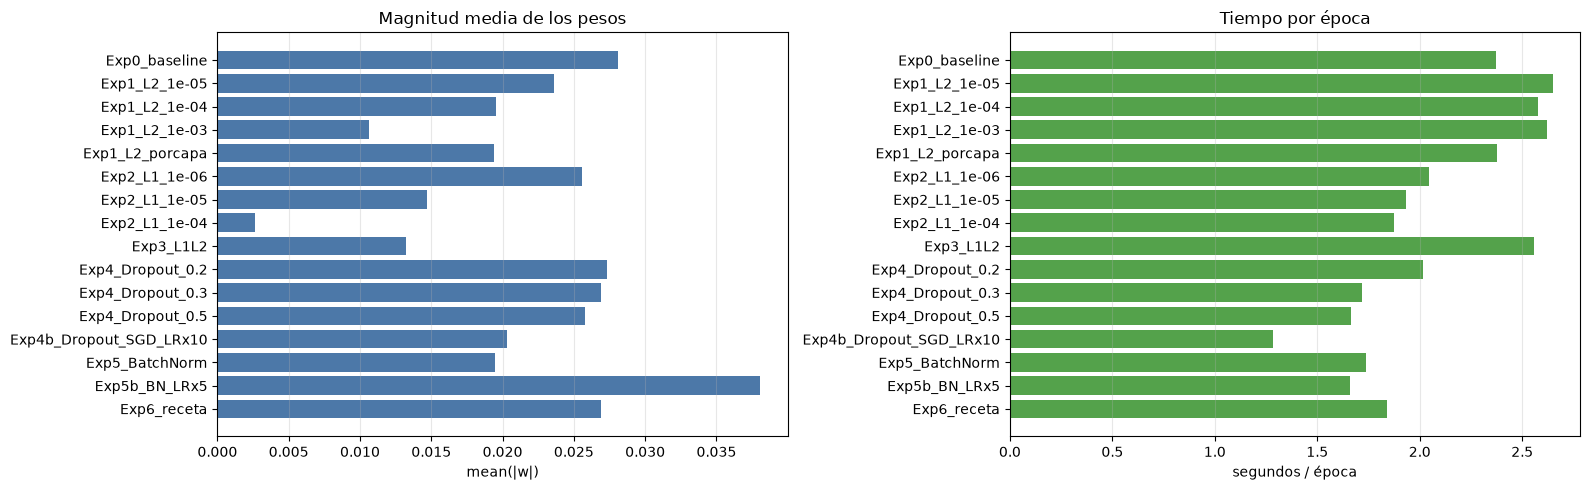

In [ ]:
# ----- Magnitud de pesos y tiempo por época -----
nombres = list(resultados_reg.keys())
mean_w = [resultados_reg[n]["weight_stats"]["mean_abs"] for n in nombres]
t_ep = [resultados_reg[n]["t_ep_mean"] for n in nombres]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].barh(nombres, mean_w, color="#4c78a8"); axes[0].set_xlabel("mean(|w|)")
axes[0].set_title("Magnitud media de los pesos"); axes[0].invert_yaxis()
axes[1].barh(nombres, t_ep, color="#54a24b"); axes[1].set_xlabel("segundos / época")
axes[1].set_title("Tiempo por época"); axes[1].invert_yaxis()
for ax in axes: ax.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()

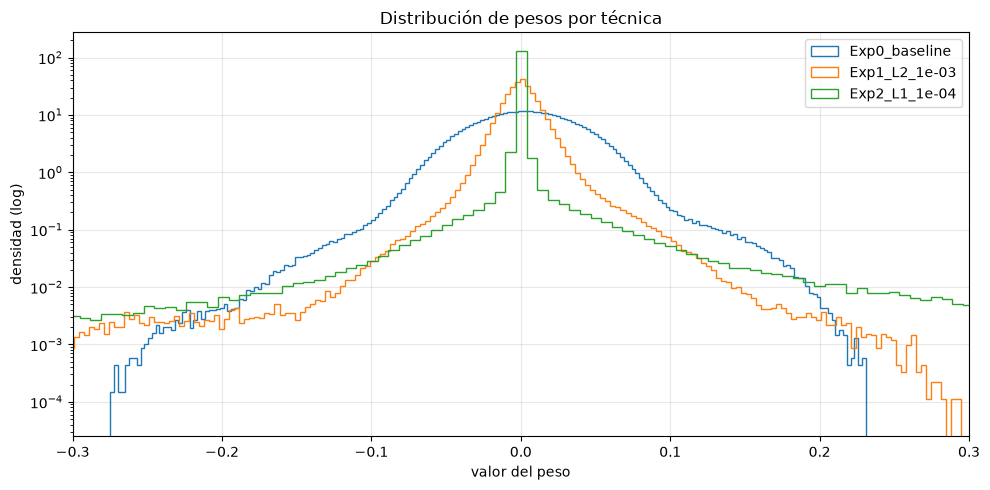

In [42]:
# ----- Histogramas de pesos: baseline vs L2 vs L1 (sparsity) -----
def _pesos(nombre):
    m = resultados_reg[nombre]["model"]
    return torch.cat([mod.weight.detach().flatten() for mod in m.modules()
                      if isinstance(mod, nn.Linear)]).cpu().numpy()

comparables = [n for n in ["Exp0_baseline", "Exp1_L2_1e-03", "Exp2_L1_1e-04"] if n in resultados_reg]
plt.figure(figsize=(10, 5))
for n in comparables:
    plt.hist(_pesos(n), bins=200, histtype="step", label=n, density=True)
plt.yscale("log"); plt.xlabel("valor del peso"); plt.ylabel("densidad (log)")
plt.title("Distribución de pesos por técnica"); plt.legend(); plt.grid(alpha=.3)
plt.xlim(-0.3, 0.3); plt.tight_layout(); plt.show()

## 9.11 Evaluación final en Test

Se elige el mejor modelo por accuracy de validación (sin mirar test) y se lo evalúa una sola vez, reutilizando la función `evaluar_y_graficar_cm`. El vectorizador usado es el ajustado solo con train (`reg_vectorizer`).

Mejor modelo por validación: Exp4_Dropout_0.3 (val_acc=0.6960)
 EVALUACIÓN DETALLADA: MLP regularizado (Exp4_Dropout_0.3)
 Accuracy en Test: 0.6317

                          precision    recall  f1-score   support

             alt.atheism       0.44      0.46      0.45       319
           comp.graphics       0.52      0.61      0.56       389
 comp.os.ms-windows.misc       0.66      0.54      0.60       394
comp.sys.ibm.pc.hardware       0.59      0.62      0.60       392
   comp.sys.mac.hardware       0.68      0.60      0.64       385
          comp.windows.x       0.72      0.65      0.68       395
            misc.forsale       0.71      0.78      0.74       390
               rec.autos       0.42      0.73      0.53       396
         rec.motorcycles       0.69      0.66      0.67       398
      rec.sport.baseball       0.91      0.69      0.78       397
        rec.sport.hockey       0.84      0.87      0.85       399
               sci.crypt       0.78      0.67      0.72   

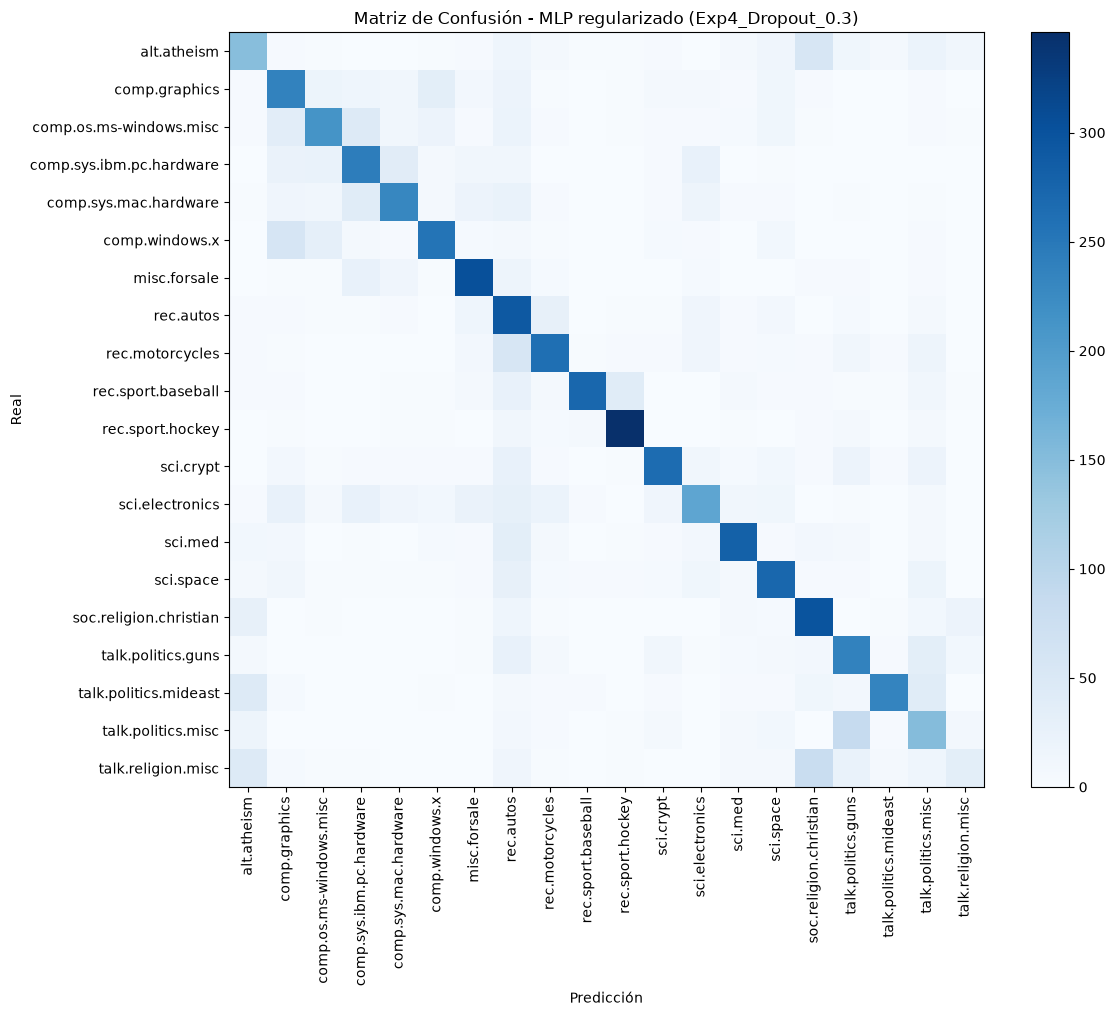

In [43]:
# Selección del mejor modelo SOLO por validación (el test no interviene en la elección)
mejor_nombre = max(resultados_reg, key=lambda k: resultados_reg[k]["val_acc"])
mejor_model = resultados_reg[mejor_nombre]["model"]
print(f"Mejor modelo por validación: {mejor_nombre} "
      f"(val_acc={resultados_reg[mejor_nombre]['val_acc']:.4f})")

# Test transformado con el vectorizador ajustado SOLO con train
X_te_reg = reg_vectorizer.transform(reg_test_texts)
reg_test_loader = DataLoader(to_tensor_dataset(X_te_reg, newsgroups_test.target),
                             batch_size=REG_BATCH, shuffle=False)

preds_reg, labels_reg = evaluar_y_graficar_cm(
    model=mejor_model, test_loader=reg_test_loader,
    class_names=class_names, model_name=f"MLP regularizado ({mejor_nombre})", device=device)

## 10. Búsqueda con Optuna incluyendo regularización 

Acá se deja que Optuna elija la mejor combinaciónn de regularización para obtener un modelo final.

Se mantienen fijos el preprocesamiento y la arquitectura del baseline de 10.2 (la arquitectura ya se exploró en la búsqueda del MLP base). Optuna busca:
- `esquema` ∈ {`l1l2`, `dropout`, `batchnorm`, `receta`};
- `lr` y los hiperparámetros propios de cada esquema (`l1`, `l2`, `dropout`, `max_norm`).

Se usa solo train/validación, pruning (`MedianPruner`) + Early Stopping. Se reutilizan `train_model_reg`, `tracked` y MLflow.

NOTA: cuando se habla de "Receta", se refiere a la combinación dropout + max_norm, así la nombramos en clase.

In [ ]:
# Cantidad de trials de la búsqueda con regularización 
N_TRIALS_REG = 30


def objective_reg(trial):
    # Arquitectura y datos FIJOS: la búsqueda se concentra en la regularización.
    esquema = trial.suggest_categorical("esquema", ["l1l2", "dropout", "batchnorm", "receta"])
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)

    dropout, batchnorm, l1, l2, max_norm = 0.0, False, 0.0, 0.0, None
    if esquema == "l1l2":
        l1 = trial.suggest_float("l1", 1e-7, 1e-4, log=True)
        l2 = trial.suggest_float("l2", 1e-6, 1e-3, log=True)
    elif esquema == "dropout":
        dropout = trial.suggest_float("dropout", 0.2, 0.5)
    elif esquema == "batchnorm":
        batchnorm = True
    else:  # dropout + max_norm
        dropout = trial.suggest_float("dropout", 0.2, 0.5)
        max_norm = trial.suggest_categorical("max_norm", [3.0, 4.0, 5.0])

    torch.manual_seed(REG_SEED)
    model = MLPConfigurableReg(REG_INPUT_DIM, REG_HIDDEN, NUM_CLASSES, REG_ACT,
                               dropout=dropout, batchnorm=batchnorm, weight_init=REG_INIT)
    optimizer = optim.Adam(model.parameters(), lr=lr)

    g_reg.manual_seed(REG_SEED)
    hist = train_model_reg(model, reg_train_loader, reg_val_loader, optimizer,
                           epochs=25, run_name=f"reg_trial_{trial.number}",
                           l1=l1, l2=l2, max_norm=max_norm,
                           early_stopping=8, es_monitor="val_acc",
                           restore_best=False, trial=trial, verbose=False)
    be = hist["best_epoch"]
    return hist["val_acc"][be]


mlflow.end_run()
mlflow.set_experiment("mlp_reg_20newsgroups")
study_reg = optuna.create_study(
    study_name="mlp_reg_20news", storage="sqlite:///optuna_reg.db", load_if_exists=True,
    direction="maximize",
    pruner=optuna.pruners.MedianPruner(n_warmup_steps=3))
study_reg.optimize(tracked(objective_reg, "reg"), n_trials=N_TRIALS_REG)

print("\\n--- MEJOR CONFIG REGULARIZADA (Optuna) ---")
print("Mejor val_acc:", study_reg.best_value)
print("Mejores hiperparámetros:", study_reg.best_params)

# Tabla de la búsqueda 
df_trials_reg = study_reg.trials_dataframe(attrs=("number", "value", "state", "params"))
df_trials_reg

2026/11/18 01:26:54 INFO mlflow.tracking.fluent: Experiment with name 'mlp_reg_20newsgroups' does not exist. Creating a new experiment.
[I 2026-11-18 01:26:54,780] A new study created in RDB with name: mlp_reg_20news
[I 2026-11-18 01:27:13,707] Trial 0 finished with value: 0.6725585505965532 and parameters: {'esquema': 'receta', 'lr': 0.005432717824625701, 'dropout': 0.3822849051197184, 'max_norm': 4.0}. Best is trial 0 with value: 0.6725585505965532.
[I 2026-11-18 01:27:31,904] Trial 1 finished with value: 0.6760936809544852 and parameters: {'esquema': 'receta', 'lr': 0.005082604628022985, 'dropout': 0.4047876547279512, 'max_norm': 4.0}. Best is trial 1 with value: 0.6760936809544852.
[I 2026-11-18 01:27:57,369] Trial 2 finished with value: 0.6672558550596553 and parameters: {'esquema': 'l1l2', 'lr': 0.006196601819935533, 'l1': 1.1557015174137554e-06, 'l2': 1.0383516317673668e-05}. Best is trial 1 with value: 0.6760936809544852.
[I 2026-11-18 01:29:00,124] Trial 3 finished with value:

\n--- MEJOR CONFIG REGULARIZADA (Optuna) ---
Mejor val_acc: 0.6977463543968184
Mejores hiperparámetros: {'esquema': 'dropout', 'lr': 0.00020251254393965703, 'dropout': 0.20514548154814066}


,number,value,state,params_dropout,params_esquema,params_l1,params_l2,params_lr,params_max_norm
0,0,0.672559,COMPLETE,0.382285,receta,NaN,NaN,0.005433,4.0
1,1,0.676094,COMPLETE,0.404788,receta,NaN,NaN,0.005083,4.0
2,2,0.667256,COMPLETE,NaN,l1l2,1.155702e-06,0.000010,0.006197,NaN
3,3,0.651348,COMPLETE,NaN,l1l2,2.359576e-06,0.000568,0.002736,NaN
4,4,0.680513,COMPLETE,0.263832,receta,NaN,NaN,0.002526,4.0
5,5,0.531595,PRUNED,NaN,l1l2,8.859081e-05,0.000027,0.000849,NaN
6,6,0.673884,COMPLETE,NaN,batchnorm,NaN,NaN,0.002633,NaN
7,7,0.695979,COMPLETE,0.370490,receta,NaN,NaN,0.000240,5.0
8,8,0.648255,PRUNED,NaN,batchnorm,NaN,NaN,0.000571,NaN
9,9,0.668140,PRUNED,NaN,batchnorm,NaN,NaN,0.001525,NaN


### 10.1 Entrenamiento final del modelo regularizado y evaluación en test

Se reconstruye la mejor configuración hallada, se entrena con Early Stopping + `ReduceLROnPlateau` y se evalúa una vez en el test reservado (reutilizando `evaluar_y_graficar_cm`).

[mlp_reg_final] 1/60 tr_acc=0.1741 val_acc=0.3849 val_loss=2.9228 |w|max=1.49 1.88s
[mlp_reg_final] 2/60 tr_acc=0.4620 val_acc=0.5205 val_loss=2.5122 |w|max=1.64 2.23s
[mlp_reg_final] 3/60 tr_acc=0.6062 val_acc=0.6266 val_loss=1.8302 |w|max=1.83 1.77s
[mlp_reg_final] 4/60 tr_acc=0.7028 val_acc=0.6690 val_loss=1.4301 |w|max=1.95 1.68s
[mlp_reg_final] 5/60 tr_acc=0.7537 val_acc=0.6752 val_loss=1.2347 |w|max=2.03 1.62s
[mlp_reg_final] 6/60 tr_acc=0.7963 val_acc=0.6929 val_loss=1.1319 |w|max=2.10 1.72s
[mlp_reg_final] 7/60 tr_acc=0.8312 val_acc=0.6916 val_loss=1.0770 |w|max=2.15 1.59s
[mlp_reg_final] 8/60 tr_acc=0.8574 val_acc=0.6977 val_loss=1.0462 |w|max=2.19 1.53s
[mlp_reg_final] 9/60 tr_acc=0.8810 val_acc=0.6920 val_loss=1.0291 |w|max=2.23 1.65s
[mlp_reg_final] 10/60 tr_acc=0.8958 val_acc=0.6898 val_loss=1.0235 |w|max=2.27 1.57s
[mlp_reg_final] 11/60 tr_acc=0.9116 val_acc=0.6871 val_loss=1.0243 |w|max=2.30 1.58s
[mlp_reg_final] 12/60 tr_acc=0.9266 val_acc=0.6840 val_loss=1.0315 |w|max=

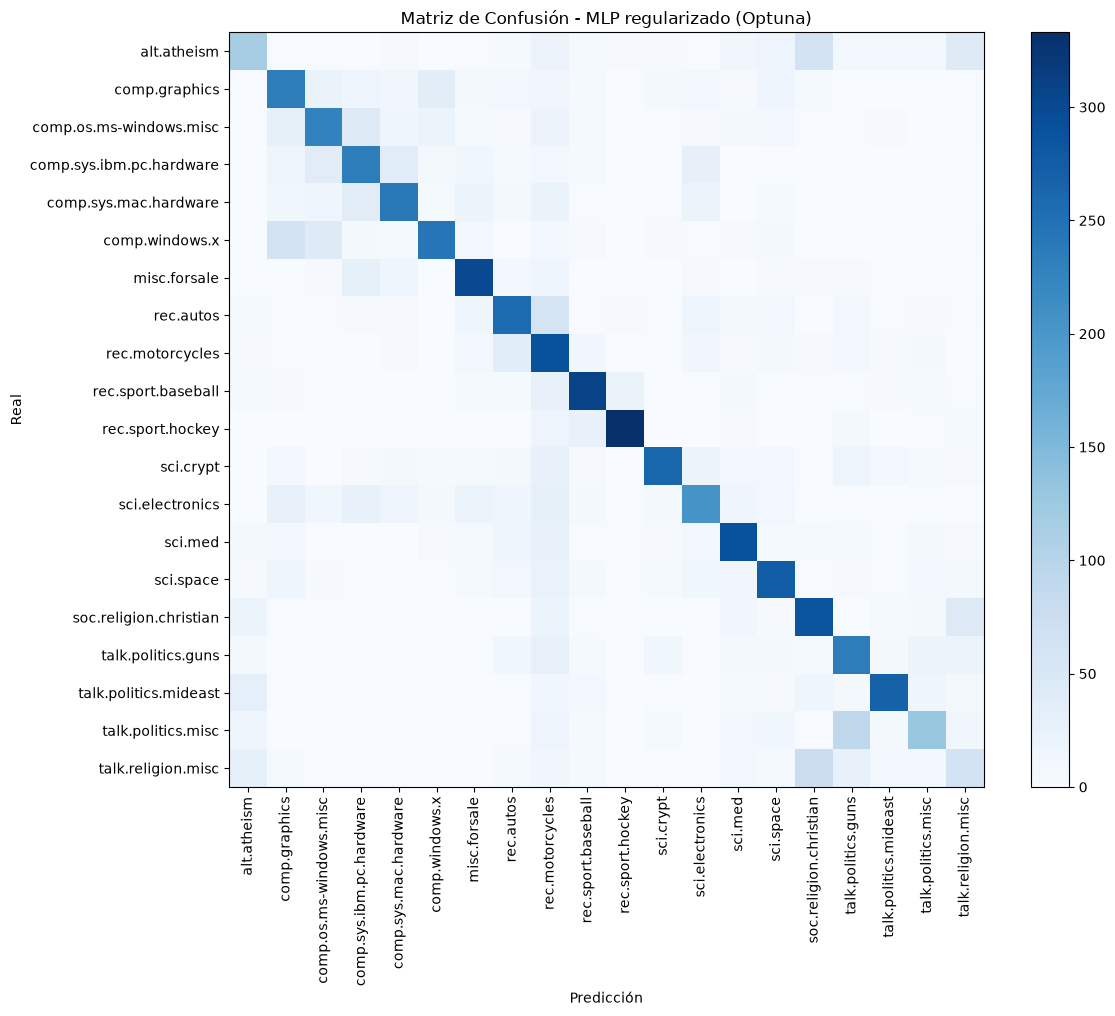

In [ ]:
def _reg_knobs(bp):
    """Traduce los best_params de Optuna a kwargs del modelo y del entrenamiento."""
    mk = dict(dropout=0.0, batchnorm=False)
    tk = dict(l1=0.0, l2=0.0, max_norm=None)
    esquema = bp["esquema"]
    if esquema == "l1l2":
        tk["l1"], tk["l2"] = bp["l1"], bp["l2"]
    elif esquema == "dropout":
        mk["dropout"] = bp["dropout"]
    elif esquema == "batchnorm":
        mk["batchnorm"] = True
    else:  # receta
        mk["dropout"], tk["max_norm"] = bp["dropout"], bp["max_norm"]
    return mk, tk


bp = study_reg.best_params
mk, tk = _reg_knobs(bp)

torch.manual_seed(REG_SEED)
model_reg_opt = MLPConfigurableReg(REG_INPUT_DIM, REG_HIDDEN, NUM_CLASSES, REG_ACT,
                                   weight_init=REG_INIT, **mk)
opt_reg = optim.Adam(model_reg_opt.parameters(), lr=bp["lr"])
sched_reg = optim.lr_scheduler.ReduceLROnPlateau(opt_reg, mode="min", factor=0.1,
                                                 patience=5, min_lr=1e-5)

mlflow.end_run()
mlflow.set_experiment("mlp_reg_20newsgroups")
with mlflow.start_run(run_name="mlp_reg_final"):
    mlflow.log_params(bp)
    g_reg.manual_seed(REG_SEED)
    hist_reg_opt = train_model_reg(model_reg_opt, reg_train_loader, reg_val_loader, opt_reg,
                                   epochs=60, run_name="mlp_reg_final",
                                   early_stopping=15, es_monitor="val_acc",
                                   restore_best=True, scheduler=sched_reg, **tk)

be = hist_reg_opt["best_epoch"]
print(f"Modelo regularizado (Optuna) | mejor val_acc={hist_reg_opt['val_acc'][be]:.4f} (época {be+1})")

# Evaluación en TEST 
preds_reg_opt, labels_reg_opt = evaluar_y_graficar_cm(
    model=model_reg_opt, test_loader=reg_test_loader,
    class_names=class_names, model_name="MLP regularizado (Optuna)", device=device)

# 11. Análisis e interpretación de los resultados 

Todos los experimentos compartieron la misma configuración (TF-IDF de 5000 features, MLP `[512, 256]` con ReLU e inicialización Glorot, Adam con `lr=1e-3`, partición train/validación 80/20 con semilla fija) y solo cambian la técnica de regularización. El experimento de control es `Exp0_baseline`, que en su mejor época (3) alcanza val_acc = 0,681 con train_acc = 0,902 (brecha 0,221) y luego, si se lo deja seguir, memoriza el training (train sube a 0,97 y se estanca) mientras la val_loss crece de 1,07 a 1,74: ese crecimiento sostenido de la loss de validación, mayor que la caída de val_acc, es la señal clara de sobreajuste contra la que se compara todo el resto.


## L2 (weight decay)

**Magnitud de pesos.** Es el efecto más limpio y esperable: al subir λ, `mean|w|` baja de forma monótona (0,0281 en el baseline → 0,0236 con 1e-5 → 0,0195 con 1e-4 → 0,0106 con 1e-3). Esto coincide con la teoría: L2 agrega el término λ‖w‖² que multiplica cada peso por un factor (1−2ηλ) < 1 en cada paso, comprimiendo la distribución hacia el origen sin llevar ningún peso a cero exacto.

**Curvas.** Con λ = 1e-5 y 1e-4 la trayectoria es casi igual a la del baseline: el train igual termina saturando en 0,97 y la val_loss igual diverge (1,07 → 1,48). La "brecha" chica que muestra la tabla (0,09–0,10) se debe sobre todo a que la mejor época quedó en la 2, antes de que el train saturara, no a que L2 haya aplanado el entrenamiento. En cambio con λ = 1e-3 sí se ve regularización real: el train no pasa de ~0,92 y la val_loss se queda plana en ~1,2 en vez de dispararse. El costo es que la val_acc baja un poco (0,659 contra 0,681), señal de que ese λ ya empieza a restringir demás (subajuste).

**Comparación interna.** La variante por capa (más λ en las capas cercanas a la salida) dio prácticamente lo mismo que 1e-4 (val 0,678, `mean|w|` 0,0194) con la brecha más chica de la familia L2 (0,083), pero sin una mejora apreciable en validación.

**Lectura.** L2 hace lo que promete sobre los pesos, pero en este problema no mejora la generalización: la val_acc se queda igual o algo por debajo del baseline. Su aporte real es controlar la divergencia de la val_loss cuando λ es suficientemente grande.


## L1 y poda

**Magnitud de pesos.** L1 es mucho más agresivo que L2 para achicar la masa total: con λ = 1e-4 el `mean|w|` se desploma a 0,0026 (un orden de magnitud por debajo del baseline). Pero al mismo tiempo el `max|w|` sube a 0,788 (y la norma de fila máxima a 5,49, la más alta de todos los experimentos). Esa combinación de promedio bajísimo pero máximo alto es característica de L1: el paso constante ±λ empuja a cero la mayoría de los pesos poco útiles y deja sobrevivir unos pocos que concentran la información.

**Esparsidad y poda.** Con Adam, L1 no produce ceros exactos (`frac_zero` ≈ 0,006), sino muchos pesos muy chicos; la esparsidad se demuestra con la poda explícita.

Sobre el modelo podado (que fue el de λ = 1e-6, el de mejor validación y casi sin regularizar) se puede llevar a cero el 50 % de las conexiones con un umbral de 0,02 sin perder accuracy (0,684 vs 0,680), bajar al 12,5 % con una caída leve (0,658) y recién al quedar 1,3 % de los pesos la red colapsa (0,17). Esto muestra que la red está fuertemente sobreparametrizada, la mayoría de las conexiones son redundantes.

**Curvas.** Con λ = 1e-4 el entrenamiento se frena notablemente (train recién llega a 0,70 en la época 7, contra la época 2–3 del baseline), porque la penalización constante le pelea al crecimiento de los pesos desde el inicio. La validación hace pico en 0,635 (época 12) y después cae: el modelo subajusta con λ demasiado alto.

**Lectura.** L1 sirve para esparsificar y seleccionar features, no para mejorar la validación en este caso. El λ útil es chico (1e-5, con brecha 0,075 y val 0,678); 1e-4 ya castiga de más.


## L1 + L2 (ElasticNet)

Combina las dos: achica los pesos como L2 (`mean|w|` 0,0132, intermedio) y produce la brecha más chica (0,065) en su mejor época (época 2), con val 0,6717. No obstante no supera al baseline en validación (0,6717 contra 0,681). La conclusión es la que ya se anticipó en clase (en redes neuronales ElasticNet es poco frecuente) y lo que se ve acá: combinarlas no aporta nada que no diera cada una por separado, y agrega dos hiperparámetros para ajustar.


## Dropout

**Magnitud de pesos.** A diferencia de L1/L2, Dropout no achica los pesos: `mean|w|` se mantiene en ~0,026–0,027, igual que el baseline. Dropout no regulariza penalizando la magnitud, sino inyectando ruido que rompe las co-adaptaciones entre neuronas. Son dos mecanismos distintos.

**Curvas.** Es la técnica que mejor generaliza de toda la sección: val_acc de 0,695 / 0,696 / 0,692 con p = 0,2 / 0,3 / 0,5, por encima del baseline (0,681). La brecha baja de forma monótona al subir p (0,165 → 0,134 → 0,066 en la época 3), y con p = 0,5 la validación queda estable en ~0,69 mientras el train sigue subiendo. También se ve el efecto característico de que al inicio la validación supera al train (p = 0,5, época 1: train 0,24 con la red "amputada" por el dropout vs val 0,56 con la red completa).

**Épocas y learning rate.** Siguiendo la recomendación de clase se corrió con más épocas (80) y early stopping, pero con Adam la mejor época fue la 3 y el early stopping cortó en la 18, las épocas extra no se aprovecharon. 

**Lectura.** Dropout es la estrategia más efectiva acá, ya que mejora (levemente) la validación y reduce la brecha sin tocar la magnitud de los pesos.


## Batch Normalization

**Curvas y velocidad.** BN hace lo que se esperaba en cuanto a convergencia: llega al 95 % de train_acc en la **época 2** (contra la 4 del baseline) y la val_acc es muy estable y suave (se mantiene en ~0,665 sin caer). La val_loss sube mucho menos que en el baseline (1,16 → 1,36 contra 1,07 → 1,74), es decir que estabiliza el entrenamiento.

**Magnitud de pesos.** Mantiene la norma de fila más baja de todos (1,81 contra 3,51 del baseline), coherente con que la normalización por batch evita que las activaciones y los pesos crezcan demasiado.

BN tiene la mayor brecha train–val de toda la sección (0,300), con train 0,971 y val 0,671, y no mejora la validación (0,671 contra 0,681). Esto confirma lo visto en clase: en esta red de solo dos capas, BN acelera y estabiliza, pero su efecto regularizador es secundario. La variante con lr ×5 (`Exp5b`) tampoco mejoró (0,666) y su val_loss mínima apareció ya en la época 1: subir el learning rate con BN acelera, pero también adelanta el sobreajuste.

**Tiempos.** Se esperaba un costo por época algo mayor por los cálculos extra del batch, pero no se distingue del ruido de medición, así que no es posible afirmarlo con estos datos.


## Dropout + Max-Norm + Early Stopping + ReduceLROnPlateau

El resultado de `Exp6` es idéntico al de Dropout p = 0,3(val 0,696, train 0,830, brecha 0,134, `mean|w|` 0,0269). La razón se lee directamente en la tabla: la norma de fila máxima fue 3,01, por debajo del tope c = 4 de Max-Norm, así que la restricción nunca llegó a actuar, y como el early stopping volvió a cortar en la mejor época (3), el scheduler tampoco tuvo margen para intervenir. En los hechos, en este problema la "receta" se reduce a Dropout. Los pesos nunca crecieron lo suficiente para que Max-Norm con c = 4 recortara algo. Si se quisiera que esa restricción tuviera efecto, habría que bajar c a ~1,5–2.


## Búsqueda con Optuna 

La búsqueda sobre esquemas de regularización (30 trials) coincide con el análisis controlado: la mejor configuración fue **Dropout con p = 0,205 y lr = 2e-4** (val 0,698), y casi todas las mejores quedaron en esquemas con dropout. Dos cosas interesantes respecto del learning rate: el mejor lr encontrado (2e-4) es más bajo que el 1e-3 del baseline, y los trials con lr alto (~5e-3–8e-3) dieron peor validación o fueron podados. Es decir, en este caso un learning rate más bajo generalizó mejor, consistente con la trayectoria del modelo final (sube suave hasta val 0,698 en la época 8 y luego la val_loss empieza a subir).


## Comparación general y conclusiones

Sobre la magnitud de los pesos, las técnicas se separan en tres grupos claros:
- L1 y L2 achican los pesos (es su mecanismo): L2 de forma uniforme, L1 de forma esparsa (promedio muy bajo + unos pocos pesos grandes).
- Dropout no toca la magnitud (`mean|w|` parecido al baseline): regulariza por ruido, no por penalización.
- BN mantiene las normas bajas por la normalización, no por una penalización explícita.

Sobre la generalización, ninguna técnica mejora mucho la validación: el baseline ya rinde ~0,68 en su mejor época y lo máximo que se consigue es ~0,69–0,70 con Dropout. Lo que sí cambia bastante es el control del sobreajuste: todas reducen la brecha train–val y/o frenan la divergencia de la val_loss. El techo de validación de este problema (TF-IDF + MLP de dos capas sobre 20 Newsgroups) parece estar en ~0,70, y la regularización sirve más para llegar a ese techo de forma estable que para superarlo.

Sobre los tiempos, el costo por época no es distinguible entre técnicas (ruido de medición). La diferencia real de costo está en las épocas hasta converger: Adam con Dropout/BN llega en pocas épocas, mientras que la "receta" con SGD + lr ×10 necesitó ~57 épocas. Early stopping fue clave en todos: la mejor época casi siempre cayó en la 2–3.

Sobre el learning rate, lo obtenido apunta a lr bajo: el baseline con lr = 1e-3 ya hace pico muy temprano y después sobreajusta; subirlo (BN ×5, SGD ×10) acelera pero adelanta el sobreajuste o exige muchas más épocas; y Optuna eligió lr = 2e-4 como mejor.

Evaluación en test: tanto el mejor modelo controlado (Dropout 0,3) como el mejor de Optuna (Dropout, lr 2e-4) dan prácticamente lo mismo en test: 0,632 y 0,635 de accuracy. La caída val → test (~0,70 → ~0,63) es de ~6–7 puntos y es consistente entre ambos modelos, lo que sugiere que se debe a la naturaleza de la partición oficial del dataset (train y test separados en el tiempo) más que a un sobreajuste a validación. Por clases, las mejores son las de temática bien separadas y las peores las semánticamente solapadas, un patrón habitual en este dataset.

**Conclusión.** En esta red chica y con estas features, la regularización no rompió el techo de ~0,70 en validación, pero el experimento cumple su objetivo: se ve con claridad que L1/L2 operan sobre la magnitud de los pesos, que Dropout generaliza algo mejor sin tocar esa magnitud, y que BN acelera y estabiliza pero casi no regulariza en una red de dos capas. La estrategia que mejor combinó buena validación y brecha controlada fue **Dropout** (p entre 0,2 y 0,3), y es coherente que tanto el análisis controlado como la búsqueda automática hayan llegado a la misma conclusión.
